# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | SimCLR Notebook |
| **Assignment 01 Decoder** | Segformer |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 18 Augest 2026 |

# SimCLR Self-Supervised Pretraining for Semantic Segmentation
### CSE 438 — Assignment Part B (SSL Methods) — Kvasir Capsule Endoscopy Segmentation

**AI-assistance disclosure (per Assignment Part B, Section 7 — AI Usage Policy):**
This notebook's data-loading and model/training code was drafted with the assistance
of an AI coding tool (boilerplate architecture, training-loop scaffolding, and library
API usage) and then adapted to this dataset. Every non-trivial block below carries a
`# AI-assisted` comment as required by the policy. The reasoning in this notebook's
discussion/markdown cells that report *why* something happened (e.g. Task E's
label-efficiency discussion, Task F's error analysis) is deliberately left as
structured prompts for you to fill in yourselves — per the same policy, that
reasoning must be your own, and it is exactly what the viva will test.

## What Self-Supervised Learning (SSL) is
Self-supervised learning trains an encoder to produce useful image representations
by solving a *pretext task* defined only from the raw pixels of unlabelled images —
no human class label or mask is ever shown to the encoder during this stage. SimCLR's
pretext task is contrastive: two independently-augmented "views" of the same image
should be pulled together in representation space, while views of *different* images
should be pushed apart. The signal that trains the encoder comes entirely from the
augmentation pipeline and the identity of "which crop came from which image" — never
from a class label.

## Why SimCLR specifically
SimCLR (Chen et al., ICML 2020) is one of the most influential contrastive SSL
methods because it showed that a conceptually simple recipe — two augmented views,
a shared encoder, a small projection head, and the NT-Xent contrastive loss — can
match or approach supervised ImageNet pretraining, given a large enough batch size
and a strong augmentation policy. It is the natural first baseline against which
BYOL (negative-free), MAE (masked reconstruction), and DINOv2 (self-distillation)
are compared in this assignment, since it is the most direct instance of the
"contrastive matching" pretext-task family in Section 1.1 of the brief.

## Why representation learning matters for this dataset
Kvasir capsule-endoscopy contamination segmentation masks (Clear / Bubble / Turbid)
are expensive to produce — a trained annotator has to trace contamination boundaries
frame-by-frame. Raw endoscopy frames, by contrast, are comparatively cheap to collect.
If an encoder that has only ever seen *unlabelled* frames can be fine-tuned to strong
segmentation accuracy using a small labelled subset, that directly lowers the
annotation burden for any future dataset of this kind — which is the central
label-efficiency question Task E asks.

## Why this notebook reuses the Data-Preparation notebook's artifacts instead of
## recreating them
The attached Data-Preparation notebook already: (1) loaded Part A's frozen
train/validation/test split byte-for-byte and mechanically verified it introduced
no leakage or reshuffling, (2) mapped each split to its SSL role (train → unlabelled
pretraining corpus, validation → labelled fine-tuning set, test → monitoring +
final evaluation), (3) built and sanity-checked the `SSLDataset` class and every
method-specific augmentation pipeline (SimCLR/BYOL/MAE/DINOv2/finetune), and
(4) exported all of this as versioned JSON/CSV artifacts. Recomputing any of that
here would risk silently diverging from what the Data-Preparation notebook already
validated — and since this exact same fork happens independently in the BYOL, MAE,
and DINOv2 notebooks, even a tiny divergence (a different random crop scale, a
re-shuffled split) would make the eventual four-way + Part-A comparison in the
Final Comparison notebook meaningless. This notebook therefore only ever *loads*
those artifacts (Section 2) and, where a Kaggle session can't literally `import` a
class from another notebook, *reproduces* the identical implementation from the
exported config rather than inventing a new one (Section 3).

## Pipeline this notebook implements
```
Load Data-Prep + Part-A Artifacts
        │
        ▼
Task A — SSL Datasets & DataLoaders (reused interfaces, not redesigned)
        │
        ▼
Task B — SimCLR Pretraining (ResNet-50 encoder, 50 epochs, NT-Xent loss)
        │
        ▼
        [ Task C-F implemented in the notebook's later sections ]
```

**Only specify `DATASET_ROOT` and the two dataset-slug lists below** — everything
else auto-resolves and runs top-to-bottom.

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
# AI-assisted: standard import block, adapted to this project's stack.
from __future__ import annotations

import os
import json
import math
import time
import random
import platform
import warnings
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass
from typing import Any, Optional

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as Fnn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

print("Imports complete.")
print(f"  torch          : {torch.__version__}")
print(f"  torchvision    : {torchvision.__version__}")
print(f"  albumentations : {A.__version__}")
print(f"  opencv-python  : {cv2.__version__}")
print(f"  numpy          : {np.__version__}")
print(f"  pandas         : {pd.__version__}")
print(f"  CUDA available : {torch.cuda.is_available()}")

Imports complete.
  torch          : 2.10.0+cu128
  torchvision    : 0.25.0+cu128
  albumentations : 2.0.8
  opencv-python  : 4.13.0
  numpy          : 2.0.2
  pandas         : 2.3.3
  CUDA available : True


In [2]:
# ============================================================================
# GLOBAL CONFIGURATION
# ============================================================================

EXPERIMENT_NAME = "simclr_resnet50_kvasir_ssl"

# -----------------------------------------------------------------------------
# Kaggle Input Information
# -----------------------------------------------------------------------------
KAGGLE_USERNAME = "nasrullahsijan"

# Part A (Fully-supervised preprocessing) notebook output
PART_A_DATASET_SLUGS = [
    "data-preprocessing-tasks-b-d",
]

# Data-Preparation (SSL preprocessing) notebook output
DATA_PREP_DATASET_SLUGS = [
    "data-preparation-notebook",
]

# -----------------------------------------------------------------------------
# Original Kvasir Dataset
# -----------------------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/nasrullahsijan/"
    "kvasir-capsule-endoscopy/"
    "Kvasir capsule endoscopy dataset"
)

# -----------------------------------------------------------------------------
# Attached Notebook Outputs
# -----------------------------------------------------------------------------
PART_A_ROOT = Path(
    "/kaggle/input/notebooks/nasrullahsijan/"
    "data-preprocessing-tasks-b-d"
)

DATA_PREP_ROOT = Path(
    "/kaggle/input/notebooks/nasrullahsijan/"
    "data-preparation-notebook"
)

# -----------------------------------------------------------------------------
# SimCLR Configuration
# -----------------------------------------------------------------------------
SIMCLR_CONFIG: dict[str, Any] = {
    "experiment_name": EXPERIMENT_NAME,
    "backbone": "resnet50",
    "batch_size": 32,
    "epochs": 50,
    "learning_rate": 3e-4,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "temperature": 0.5,
    "projection_dim": 128,
    "hidden_dim": 2048,
    "weight_decay": 1e-6,
    "image_size": None,
    "random_seed": 42,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "mixed_precision": torch.cuda.is_available(),
    "gradient_clip_norm": 5.0,
    "checkpoint_interval": 20,
    "output_dir": "results/simclr",
}

# -----------------------------------------------------------------------------
# Random Seed
# -----------------------------------------------------------------------------
RANDOM_SEED = SIMCLR_CONFIG["random_seed"]
DEVICE = torch.device(SIMCLR_CONFIG["device"])


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)

torch.backends.cudnn.benchmark = True

# -----------------------------------------------------------------------------
# Matplotlib
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})

# -----------------------------------------------------------------------------
# Output Directories
# -----------------------------------------------------------------------------
OUTPUT_DIR = Path(SIMCLR_CONFIG["output_dir"])

CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"
CONFIG_DIR = OUTPUT_DIR / "config"
LOGS_DIR = OUTPUT_DIR / "logs"
REPORTS_DIR = OUTPUT_DIR / "reports"
FIGURES_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "model"
EVAL_DIR = OUTPUT_DIR / "evaluation"
ERROR_DIR = OUTPUT_DIR / "error_analysis"
SUMMARY_DIR = OUTPUT_DIR / "summary"

for d in (
    CHECKPOINTS_DIR,
    CONFIG_DIR,
    LOGS_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    MODEL_DIR,
    EVAL_DIR,
    ERROR_DIR,
    SUMMARY_DIR,
):
    d.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# Environment Information
# -----------------------------------------------------------------------------
version_log = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "albumentations_version": A.__version__,
    "opencv_version": cv2.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "execution_timestamp": datetime.now().isoformat(timespec="seconds"),
}

print("=" * 70)
print("Environment")
print("=" * 70)

for k, v in version_log.items():
    print(f"{k:<24}: {v}")

print("\nAttached Inputs")
print("-" * 70)
print("Raw Dataset      :", DATASET_ROOT)
print("Part A Notebook  :", PART_A_ROOT)
print("Data-Prep Notebook:", DATA_PREP_ROOT)

Environment
python_version          : 3.12.13
torch_version           : 2.10.0+cu128
torchvision_version     : 0.25.0+cu128
albumentations_version  : 2.0.8
opencv_version          : 4.13.0
cuda_available          : True
gpu_name                : Tesla T4
execution_timestamp     : 2026-08-15T19:17:28

Attached Inputs
----------------------------------------------------------------------
Raw Dataset      : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset
Part A Notebook  : /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d
Data-Prep Notebook: /kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook


In [3]:
# ============================================================================
# DISPLAY CONFIGURATION AS A PUBLICATION-QUALITY TABLE
# ============================================================================
_config_display_rows = [
    {"Parameter": k, "Value": v} for k, v in SIMCLR_CONFIG.items()
]
config_df = pd.DataFrame(_config_display_rows)
display(Markdown("### SimCLR Pretraining Configuration"))
display(config_df.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

### SimCLR Pretraining Configuration

Parameter,Value
experiment_name,simclr_resnet50_kvasir_ssl
backbone,resnet50
batch_size,32
epochs,50
learning_rate,0.000300
optimizer,AdamW
scheduler,CosineAnnealingLR
temperature,0.500000
projection_dim,128
hidden_dim,2048


---
# Section 2 — Load Data-Preparation Artifacts

No preprocessing, splitting, role-mapping, or augmentation-pipeline *design*
happens in this notebook. Everything in this section only loads files the
Data-Preparation notebook already produced and validated. This guarantees:

- **Reproducibility** — every SSL method (SimCLR, BYOL, MAE, DINOv2) starts
  from byte-identical splits, role mapping, and augmentation configuration.
- **No train/test leakage** — the leakage checks already ran once, in the
  Data-Preparation notebook; re-deriving the split here would risk silently
  reintroducing exactly the failure mode that notebook's Section 3 exists to
  prevent.
- **A fair four-way comparison** — SimCLR's, BYOL's, MAE's, and DINOv2's
  results in the Final Comparison notebook are only meaningful if all four
  notebooks saw the same images in the same roles.

Two separate Kaggle inputs are required: **Part A's** output (for the frozen
`train.csv` / `validation.csv` / `test.csv` splits and `label_mapping.json`)
and the **Data-Preparation notebook's** own output (for the `ssl_*` metadata
and per-method augmentation configs it derived from Part A's split).

In [4]:
from pathlib import Path

notebook_root = Path("/kaggle/input/notebooks/nasrullahsijan")

if notebook_root.exists():
    for p in notebook_root.iterdir():
        print(p)

/kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook
/kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d


In [5]:
# ============================================================================
# ARTIFACT ROOTS
# ============================================================================

class RequiredArtifactMissingError(FileNotFoundError):
    """Raised when a required artifact cannot be found."""


# --------------------------------------------------------------------------
# Part A notebook output
# --------------------------------------------------------------------------
PART_A_OUTPUT_DIR = (
    Path("/kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d")
    / "results"
)

# --------------------------------------------------------------------------
# Data-Preparation notebook output
# --------------------------------------------------------------------------
DATA_PREP_OUTPUT_DIR = (
    Path("/kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook")
    / "results"
)

# --------------------------------------------------------------------------
# Validate required files
# --------------------------------------------------------------------------
required_files = {
    "Part A": PART_A_OUTPUT_DIR / "splits" / "train.csv",
    "Data-Preparation": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_role_mapping.json",
}

for name, path in required_files.items():
    if not path.exists():
        raise RequiredArtifactMissingError(
            f"{name} artifact missing:\n{path}"
        )

print("✓ Part A Output       :", PART_A_OUTPUT_DIR)
print("✓ Data-Prep Output    :", DATA_PREP_OUTPUT_DIR)

✓ Part A Output       : /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results
✓ Data-Prep Output    : /kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook/results


In [6]:
# ============================================================================
# LOAD + VERIFY ALL REQUIRED ARTIFACTS
# ============================================================================
REQUIRED_ARTIFACTS = {
    # -- from Part A --
    "train.csv": PART_A_OUTPUT_DIR / "splits" / "train.csv",
    "validation.csv": PART_A_OUTPUT_DIR / "splits" / "validation.csv",
    "test.csv": PART_A_OUTPUT_DIR / "splits" / "test.csv",
    "label_mapping.json": PART_A_OUTPUT_DIR / "metadata" / "label_mapping.json",
    "preprocessing_metadata.json": PART_A_OUTPUT_DIR / "metadata" / "preprocessing_metadata.json",
    "part_a_augmentation_config.json": PART_A_OUTPUT_DIR / "augmentation" / "augmentation_config.json",
    # -- from the Data-Preparation (Part B / SSL) notebook --
    "ssl_preprocessing_metadata.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_preprocessing_metadata.json",
    "ssl_role_mapping.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_role_mapping.json",
    "ssl_augmentation_config.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_augmentation_config.json",
    "ssl_dataset_statistics.csv": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_dataset_statistics.csv",
    "environment_info.json": DATA_PREP_OUTPUT_DIR / "metadata" / "environment_info.json",
}
# Optional, informational only -- not required for any later step.
_manifest_candidates = [
    PART_A_OUTPUT_DIR / "metadata" / "dataset_manifest.csv",
    PART_A_OUTPUT_DIR / "dataset" / "dataset_master.csv",
]

_missing = {name: p for name, p in REQUIRED_ARTIFACTS.items() if not p.is_file()}
if _missing:
    raise RequiredArtifactMissingError(
        "Missing required artifact(s):\n" +
        "\n".join(f"  {name} -> expected at {p}" for name, p in _missing.items())
    )
print(f"All {len(REQUIRED_ARTIFACTS)} required artifacts found.")

train_df = pd.read_csv(REQUIRED_ARTIFACTS["train.csv"])
validation_df = pd.read_csv(REQUIRED_ARTIFACTS["validation.csv"])
test_df = pd.read_csv(REQUIRED_ARTIFACTS["test.csv"])

with open(REQUIRED_ARTIFACTS["label_mapping.json"]) as f:
    label_mapping = json.load(f)
with open(REQUIRED_ARTIFACTS["preprocessing_metadata.json"]) as f:
    preprocessing_metadata = json.load(f)
with open(REQUIRED_ARTIFACTS["part_a_augmentation_config.json"]) as f:
    part_a_augmentation_config = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_preprocessing_metadata.json"]) as f:
    ssl_preprocessing_metadata = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_role_mapping.json"]) as f:
    ssl_role_mapping = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_augmentation_config.json"]) as f:
    AUGMENTATION_CONFIG = json.load(f)
ssl_dataset_statistics = pd.read_csv(REQUIRED_ARTIFACTS["ssl_dataset_statistics.csv"])
with open(REQUIRED_ARTIFACTS["environment_info.json"]) as f:
    dataprep_environment_info = json.load(f)

dataset_manifest_df = None
_manifest_path = next((p for p in _manifest_candidates if p.is_file()), None)
if _manifest_path is not None:
    dataset_manifest_df = pd.read_csv(_manifest_path)
    print(f"Optional dataset manifest loaded -> {_manifest_path} ({len(dataset_manifest_df)} rows)")
else:
    print("Optional dataset manifest not found -- skipped (not required downstream).")

# Fill in image_size in SIMCLR_CONFIG from the SSL preprocessing metadata,
# rather than hard-coding it separately from what the Data-Prep notebook used.
IMAGE_SIZE = tuple(ssl_preprocessing_metadata["image_resolution"])
SIMCLR_CONFIG["image_size"] = list(IMAGE_SIZE)
print(f"IMAGE_SIZE resolved from ssl_preprocessing_metadata.json -> {IMAGE_SIZE}")

All 11 required artifacts found.
Optional dataset manifest loaded -> /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/dataset/dataset_master.csv (15143 rows)
IMAGE_SIZE resolved from ssl_preprocessing_metadata.json -> (336, 336)


In [7]:
# ============================================================================
# CROSS-CHECKS + IMAGE PATH REPAIR (Kaggle sessions sometimes re-root inputs)
# ============================================================================
_checks = []

def _check(name, passed, detail=""):
    _checks.append({"Check": name, "Status": "OK" if passed else "FAIL", "Detail": detail})

_checks_seed_dp = dataprep_environment_info.get("random_seed")
_checks_seed_meta = ssl_preprocessing_metadata.get("random_seed")
_check("Metadata loaded successfully", bool(ssl_preprocessing_metadata), "")
_check("Role mapping loaded", bool(ssl_role_mapping), f"{len(ssl_role_mapping)} roles")
_check("Augmentation configuration loaded", "simclr" in AUGMENTATION_CONFIG, "simclr key present")
_check("Dataset statistics loaded", len(ssl_dataset_statistics) > 0, f"{len(ssl_dataset_statistics)} rows")
_check(
    "Image resolution matches metadata",
    list(IMAGE_SIZE) == list(ssl_preprocessing_metadata["image_resolution"]),
    f"{IMAGE_SIZE}",
)
_check(
    "Random seed matches Data-Prep notebook",
    RANDOM_SEED == _checks_seed_dp == _checks_seed_meta,
    f"this notebook={RANDOM_SEED}, environment_info={_checks_seed_dp}, ssl_metadata={_checks_seed_meta}",
)
_check(
    "Preprocessing version/timestamp logged",
    "execution_timestamp" in ssl_preprocessing_metadata,
    f"{ssl_preprocessing_metadata.get('execution_timestamp')}",
)
_check(
    "Dataset manifest integrity",
    dataset_manifest_df is None or len(dataset_manifest_df) > 0,
    "manifest optional -- present and non-empty" if dataset_manifest_df is not None else "not attached (optional)",
)

_checks_df = pd.DataFrame(_checks)
display(Markdown("### Artifact Verification"))
display(_checks_df.style.hide(axis="index"))
if not all(row["Status"] == "OK" for row in _checks):
    raise RuntimeError("One or more artifact verification checks failed -- see table above.")


def repair_image_paths(df, dataset_root, path_columns=("image_path", "binary_mask_path", "tricolour_mask_path")):
    '''If a recorded path doesn't exist on this Kaggle session (the dataset was
    re-mounted under a different root than when Part A ran), re-root it by
    matching on filename under dataset_root. No-op if every path already resolves.
    '''
    df = df.copy()
    n_repaired = 0
    for col in path_columns:
        if col not in df.columns:
            continue
        for idx, p in df[col].items():
            if pd.isna(p) or Path(p).is_file():
                continue
            candidates = list(dataset_root.rglob(Path(p).name))
            if candidates:
                df.at[idx, col] = str(candidates[0])
                n_repaired += 1
    if n_repaired:
        print(f"  Re-rooted {n_repaired} path(s) under {dataset_root}")
    return df


if not Path(train_df.iloc[0]["image_path"]).is_file():
    print("Recorded image paths do not resolve on this session -- attempting repair via DATASET_ROOT...")
    train_df = repair_image_paths(train_df, DATASET_ROOT)
    validation_df = repair_image_paths(validation_df, DATASET_ROOT)
    test_df = repair_image_paths(test_df, DATASET_ROOT)
else:
    print("Recorded image paths resolve correctly -- no repair needed.")

### Artifact Verification

Check,Status,Detail
Metadata loaded successfully,OK,
Role mapping loaded,OK,3 roles
Augmentation configuration loaded,OK,simclr key present
Dataset statistics loaded,OK,6 rows
Image resolution matches metadata,OK,"(336, 336)"
Random seed matches Data-Prep notebook,OK,"this notebook=42, environment_info=42, ssl_metadata=42"
Preprocessing version/timestamp logged,OK,2026-07-25T18:52:04
Dataset manifest integrity,OK,manifest optional -- present and non-empty


Recorded image paths resolve correctly -- no repair needed.


In [8]:
# ============================================================================
# DISPLAY LOADED SPLIT / ROLE / AUGMENTATION SUMMARY
# ============================================================================
_summary_rows = [
    {"Split": "train", "SSL Role": ssl_role_mapping["train"]["ssl_role"], "Samples": len(train_df)},
    {"Split": "validation", "SSL Role": ssl_role_mapping["validation"]["ssl_role"], "Samples": len(validation_df)},
    {"Split": "test", "SSL Role": ssl_role_mapping["test"]["ssl_role"], "Samples": len(test_df)},
]
display(Markdown("### Loaded Split Sizes and SSL Roles"))
display(pd.DataFrame(_summary_rows).style.hide(axis="index"))

print(f"Image resolution         : {IMAGE_SIZE}")
print(f"Random seed              : {RANDOM_SEED}")
print(f"Segmentation classes (binary) : {[label_mapping['0'], label_mapping['1']]}")
print(f"White-pixel label        : {label_mapping['white_pixel_label']}")
print(f"Augmentation pipelines available: "
      f"{[k for k in AUGMENTATION_CONFIG if k not in ('image_size', 'normalization', 'avoid')]}")

### Loaded Split Sizes and SSL Roles

Split,SSL Role,Samples
train,UNLABELLED,10526
validation,LABELLED,2206
test,MONITORING_AND_EVALUATION,2411


Image resolution         : (336, 336)
Random seed              : 42
Segmentation classes (binary) : ['Contaminated', 'Clear']
White-pixel label        : 1
Augmentation pipelines available: ['simclr', 'byol', 'mae', 'dinov2', 'finetune']


**No preprocessing is performed in this section** — every value above was loaded
directly from the Data-Preparation notebook's exported artifacts. This is what
guarantees reproducibility (identical splits/roles/augmentation config every time
this notebook is re-run), prevents train/test leakage (the leakage checks already
ran once upstream and are not repeated), and ensures SimCLR, BYOL, MAE, and DINOv2
all train and are evaluated on identical data.

---
# Section 3 — Task A: SSL Datasets & DataLoaders

This section does **not** redesign any preprocessing, augmentation, or split
logic. It reproduces the `SSLDataset` class and per-method augmentation
builders **exactly** as implemented and already sanity-checked in the
Data-Preparation notebook (Sections 5-6 there), reading every parameter from
`AUGMENTATION_CONFIG` (loaded in Section 2 above, from `ssl_augmentation_config.json`)
rather than hard-coding anything new. This reproduction exists only because a
Kaggle notebook session cannot `import` a class object from a *different*
notebook — the class body itself is unchanged from the Data-Preparation
notebook's own definition.

**Not recreated here** (already done, upstream, and reused unmodified):
role mapping, augmentation *design*/parameter choices, dataset re-splitting,
metadata generation, the Data-Preparation notebook's own export/sanity-check
pipeline.

In [9]:
# ============================================================================
# IMAGE / MASK UTILITIES -- identical logic to the Data-Preparation notebook
# ============================================================================
# AI-assisted: reproduced verbatim from the Data-Preparation notebook's own
# Section 5 utilities, since this notebook cannot import that module directly
# on Kaggle. Parameters (white_pixel_label, class colors) are read from the
# loaded label_mapping, not redefined.

TRICOLOUR_CLASS_COLORS_BGR = {"Clear": (255, 255, 255), "Bubble": (255, 0, 0), "Turbid": (0, 0, 255)}
TRICOLOUR_CLASS_INDEX = {"Clear": 0, "Bubble": 1, "Turbid": 2}


def read_image_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image at {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_mask_grayscale(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path}")
    return mask


def binary_mask_to_label(mask, white_pixel_label):
    is_white = mask >= 128
    if white_pixel_label == "1":
        return is_white.astype(np.uint8)
    return (~is_white).astype(np.uint8)


def tricolour_mask_to_label(mask_bgr, tolerance=60):
    pixels = mask_bgr.reshape(-1, 3).astype(np.int16)
    refs = np.array(list(TRICOLOUR_CLASS_COLORS_BGR.values()), dtype=np.int16)
    dists = np.linalg.norm(pixels[:, None, :] - refs[None, :, :], axis=2)
    nearest = np.argmin(dists, axis=1)
    return nearest.reshape(mask_bgr.shape[:2]).astype(np.uint8)


def default_tensor_conversion_transform():
    mean = tuple(AUGMENTATION_CONFIG["normalization"]["mean"])
    std = tuple(AUGMENTATION_CONFIG["normalization"]["std"])
    return A.Compose([A.Normalize(mean=mean, std=std), ToTensorV2()])


print("Image/mask utilities defined (identical to Data-Preparation notebook Section 5).")

Image/mask utilities defined (identical to Data-Preparation notebook Section 5).


In [10]:
# ============================================================================
# SSLDataset -- reproduced from the Data-Preparation notebook, unmodified logic
# ============================================================================
VALID_SSL_MODES = ("pretrain", "finetune", "test")


class SSLDataset(Dataset):
    '''One reusable Dataset class for every stage of the Part-B SSL workflow,
    shared (in implementation) across the SimCLR/BYOL/MAE/DINOv2 notebooks --
    identical to the Data-Preparation notebook's own definition. Parameterized
    by `mode` rather than one class per method, so a difference in a later
    benchmark score reflects a genuine difference in pretraining objective,
    not in data loading.
    '''

    def __init__(self, dataframe, mode, role="", binary_label_mapping=None,
                 load_tricolour_mask=False, transform=None):
        assert mode in VALID_SSL_MODES, f"mode must be one of {VALID_SSL_MODES}, got {mode!r}"
        self.dataframe = dataframe.reset_index(drop=True)
        self.mode = mode
        self.role = role
        self.binary_label_mapping = binary_label_mapping
        self.load_tricolour_mask = load_tricolour_mask
        self.transform = transform if transform is not None else (
            None if mode == "pretrain" else default_tensor_conversion_transform()
        )

    def __len__(self):
        return len(self.dataframe)

    def get_metadata(self, index):
        row = self.dataframe.iloc[index]
        return {
            "image_path": row["image_path"], "binary_mask_path": row.get("binary_mask_path"),
            "tricolour_mask_path": row.get("tricolour_mask_path"), "image_id": row["image_filename"],
            "contaminated_percent": row.get("contaminated_percent"),
            "cleanliness_label": row.get("cleanliness_label"), "role": self.role, "mode": self.mode,
        }

    def _load_binary_label(self, path):
        return binary_mask_to_label(read_mask_grayscale(path), self.binary_label_mapping["white_pixel_label"])

    def _load_tricolour_label(self, path):
        raw = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if raw is None:
            raise FileNotFoundError(f"Could not read tri-colour mask at {path}")
        return tricolour_mask_to_label(raw)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = read_image_rgb(row["image_path"])

        if self.mode == "pretrain":
            # No mask/label ever exposed here -- pretraining sees images only.
            return {"image": image, "image_id": row["image_filename"], "role": self.role, "mode": self.mode}

        binary_label = self._load_binary_label(row["binary_mask_path"])

        if self.load_tricolour_mask and pd.notna(row.get("tricolour_mask_path")):
            tricolour_label = self._load_tricolour_label(row["tricolour_mask_path"])
            transformed = self.transform(image=image, masks=[binary_label, tricolour_label])
            binary_out, tricolour_out = transformed["masks"]
            sample = {
                "image": transformed["image"],
                "mask": binary_out.long() if torch.is_tensor(binary_out) else torch.from_numpy(binary_out).long(),
                "tricolour_mask": (tricolour_out.long() if torch.is_tensor(tricolour_out)
                                   else torch.from_numpy(tricolour_out).long()),
            }
        else:
            transformed = self.transform(image=image, mask=binary_label)
            mask_out = transformed["mask"]
            sample = {"image": transformed["image"],
                      "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long()}

        sample.update({"image_id": row["image_filename"], "contaminated_percent": row.get("contaminated_percent"),
                       "cleanliness_label": row.get("cleanliness_label"), "role": self.role, "mode": self.mode})
        return sample


print("SSLDataset defined. modes:", VALID_SSL_MODES)

SSLDataset defined. modes: ('pretrain', 'finetune', 'test')


In [11]:
# ============================================================================
# SimCLR VIEW-GENERATION PIPELINE -- built from AUGMENTATION_CONFIG["simclr"]
# ============================================================================
def build_simclr_transform(config=AUGMENTATION_CONFIG["simclr"], image_size=IMAGE_SIZE):
    '''SimCLR's two-view augmentation pipeline, built from the exact parameters
    the Data-Preparation notebook exported (not re-chosen here). Called twice
    per image (independently sampled each call) to produce (view_1, view_2).
    '''
    return A.Compose([
        A.RandomResizedCrop(size=image_size, scale=tuple(config["random_resized_crop"]["scale"]),
                             p=config["random_resized_crop"]["probability"]),
        A.HorizontalFlip(p=config["horizontal_flip"]["probability"]),
        A.RandomBrightnessContrast(
            brightness_limit=config["random_brightness_contrast"]["brightness_limit"],
            contrast_limit=config["random_brightness_contrast"]["contrast_limit"],
            p=config["random_brightness_contrast"]["probability"]),
        A.CLAHE(clip_limit=config["clahe"]["clip_limit"], p=config["clahe"]["probability"]),
        A.RandomGamma(gamma_limit=tuple(config["random_gamma"]["gamma_limit"]), p=config["random_gamma"]["probability"]),
        A.GaussianBlur(blur_limit=tuple(config["gaussian_blur"]["blur_limit"]), p=config["gaussian_blur"]["probability"]),
        A.GaussNoise(std_range=tuple(config["gaussian_noise"]["std_range"]), p=config["gaussian_noise"]["probability"]),
        A.ColorJitter(brightness=config["color_jitter"]["brightness"], contrast=config["color_jitter"]["contrast"],
                       saturation=config["color_jitter"]["saturation"], hue=config["color_jitter"]["hue"],
                       p=config["color_jitter"]["probability"]),
    ])


def generate_simclr_views(image, transform):
    '''Image -> (View 1, View 2), independently sampled uint8 RGB arrays.'''
    return transform(image=image)["image"], transform(image=image)["image"]


simclr_transform = build_simclr_transform()
_to_tensor = default_tensor_conversion_transform()  # normalize + ToTensorV2, applied AFTER simclr augmentation


class SimCLRPretrainDataset(Dataset):
    '''Wraps SSLDataset(mode="pretrain") to return the two normalized,
    tensor-converted SimCLR views the contrastive loss compares, instead of
    the raw image. The underlying SSLDataset is untouched -- this class only
    adds the view-generation + tensor-conversion step Task B needs.
    '''

    def __init__(self, base_dataset, simclr_transform, to_tensor_transform):
        self.base = base_dataset
        self.simclr_transform = simclr_transform
        self.to_tensor = to_tensor_transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        raw = self.base[index]["image"]  # uint8 HWC, no augmentation applied yet
        view_1, view_2 = generate_simclr_views(raw, self.simclr_transform)
        view_1 = self.to_tensor(image=view_1)["image"]
        view_2 = self.to_tensor(image=view_2)["image"]
        return {"view_1": view_1, "view_2": view_2, "image_id": self.base.dataframe.iloc[index]["image_filename"]}


print("SimCLR view-generation pipeline built from ssl_augmentation_config.json parameters.")

SimCLR view-generation pipeline built from ssl_augmentation_config.json parameters.


In [12]:
# ============================================================================
# FINE-TUNING AUGMENTATION -- built from AUGMENTATION_CONFIG["finetune"]
# ============================================================================
def build_finetune_transform(config=AUGMENTATION_CONFIG["finetune"], normalization=AUGMENTATION_CONFIG["normalization"]):
    '''Synchronized image+mask fine-tuning augmentation, built from the exact
    parameters the Data-Preparation notebook exported.
    '''
    return A.Compose([
        A.HorizontalFlip(p=config["horizontal_flip"]["probability"]),
        A.Rotate(limit=config["rotate"]["limit"], p=config["rotate"]["probability"],
                  border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.RandomBrightnessContrast(
            brightness_limit=config["random_brightness_contrast"]["brightness_limit"],
            contrast_limit=config["random_brightness_contrast"]["contrast_limit"],
            p=config["random_brightness_contrast"]["probability"]),
        A.CLAHE(clip_limit=config["clahe"]["clip_limit"], p=config["clahe"]["probability"]),
        A.RandomGamma(gamma_limit=tuple(config["random_gamma"]["gamma_limit"]), p=config["random_gamma"]["probability"]),
        A.Normalize(mean=tuple(normalization["mean"]), std=tuple(normalization["std"])),
        ToTensorV2(),
    ])


finetune_transform = build_finetune_transform()
print("Fine-tuning synchronized augmentation pipeline built.")

Fine-tuning synchronized augmentation pipeline built.


In [13]:
# ============================================================================
# STEP 1 -- DATASET CONSTRUCTION
# ============================================================================
pretrain_base_dataset = SSLDataset(
    dataframe=train_df, mode="pretrain", role=ssl_role_mapping["train"]["ssl_role"],
)
pretrain_dataset = SimCLRPretrainDataset(pretrain_base_dataset, simclr_transform, _to_tensor)

finetune_dataset = SSLDataset(
    dataframe=validation_df, mode="finetune", role=ssl_role_mapping["validation"]["ssl_role"],
    binary_label_mapping=label_mapping, load_tricolour_mask=True, transform=finetune_transform,
)

test_dataset = SSLDataset(
    dataframe=test_df, mode="test", role=ssl_role_mapping["test"]["ssl_role"],
    binary_label_mapping=label_mapping, load_tricolour_mask=True,
    # Deterministic, no augmentation -- default_tensor_conversion_transform() only.
)

print(f"pretrain_dataset (SimCLR views) : {len(pretrain_dataset)} samples")
print(f"finetune_dataset                : {len(finetune_dataset)} samples")
print(f"test_dataset                    : {len(test_dataset)} samples")

pretrain_dataset (SimCLR views) : 10526 samples
finetune_dataset                : 2206 samples
test_dataset                    : 2411 samples


In [14]:
# ============================================================================
# STEP 2 -- DATALOADER CONSTRUCTION
# ============================================================================
NUM_WORKERS = min(4, os.cpu_count() or 1)

pretrain_loader = DataLoader(
    pretrain_dataset, batch_size=SIMCLR_CONFIG["batch_size"], shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
finetune_loader = DataLoader(
    finetune_dataset, batch_size=SIMCLR_CONFIG["batch_size"] // 2, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=False, persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_dataset, batch_size=SIMCLR_CONFIG["batch_size"] // 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=False, persistent_workers=NUM_WORKERS > 0,
)

print(f"pretrain_loader : {len(pretrain_loader)} batches (batch_size={pretrain_loader.batch_size})")
print(f"finetune_loader : {len(finetune_loader)} batches (batch_size={finetune_loader.batch_size})")
print(f"test_loader     : {len(test_loader)} batches (batch_size={test_loader.batch_size})")

pretrain_loader : 328 batches (batch_size=32)
finetune_loader : 138 batches (batch_size=16)
test_loader     : 151 batches (batch_size=16)


In [15]:
# ============================================================================
# STEP 3 -- VERIFICATION
# ============================================================================
_pretrain_batch = next(iter(pretrain_loader))
_finetune_batch = next(iter(finetune_loader))
_test_batch = next(iter(test_loader))

_verif_rows = [
    {"Loader": "pretrain (SimCLR)", "Batches": len(pretrain_loader), "Batch Size": pretrain_loader.batch_size,
     "view_1 shape": tuple(_pretrain_batch["view_1"].shape), "dtype": str(_pretrain_batch["view_1"].dtype)},
    {"Loader": "finetune", "Batches": len(finetune_loader), "Batch Size": finetune_loader.batch_size,
     "image shape": tuple(_finetune_batch["image"].shape), "mask shape": tuple(_finetune_batch["mask"].shape)},
    {"Loader": "test", "Batches": len(test_loader), "Batch Size": test_loader.batch_size,
     "image shape": tuple(_test_batch["image"].shape), "mask shape": tuple(_test_batch["mask"].shape)},
]
display(Markdown("### DataLoader Verification"))
for row in _verif_rows:
    print(row)

### DataLoader Verification

{'Loader': 'pretrain (SimCLR)', 'Batches': 328, 'Batch Size': 32, 'view_1 shape': (32, 3, 336, 336), 'dtype': 'torch.float32'}
{'Loader': 'finetune', 'Batches': 138, 'Batch Size': 16, 'image shape': (16, 3, 336, 336), 'mask shape': (16, 336, 336)}
{'Loader': 'test', 'Batches': 151, 'Batch Size': 16, 'image shape': (16, 3, 336, 336), 'mask shape': (16, 336, 336)}


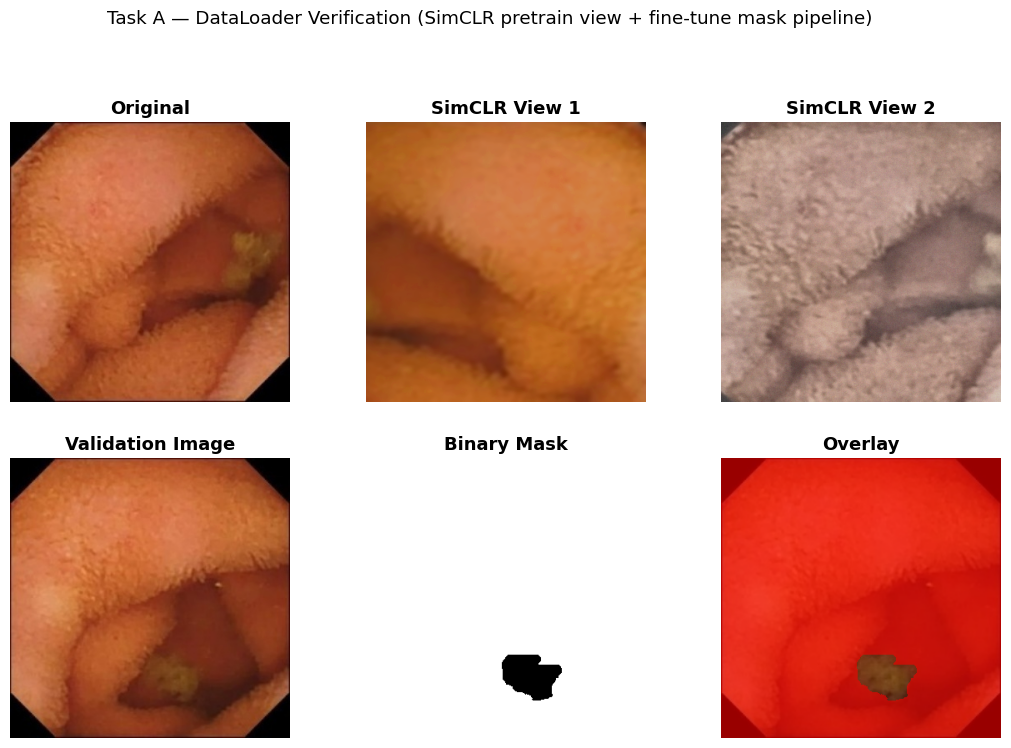

Saved -> results/simclr/figures/dataloader_verification.png


In [16]:
# ============================================================================
# STEP 4 -- QUICK VISUALIZATION (single verification figure, not another
# sanity-check section -- that already happened in the Data-Preparation notebook)
# ============================================================================
_ref_idx = 0
_raw_image = pretrain_base_dataset[_ref_idx]["image"]
_view_1, _view_2 = generate_simclr_views(_raw_image, simclr_transform)

_val_row = validation_df.iloc[_ref_idx]
_val_image = read_image_rgb(_val_row["image_path"])
_val_mask = binary_mask_to_label(read_mask_grayscale(_val_row["binary_mask_path"]), label_mapping["white_pixel_label"])

_mean = np.array(AUGMENTATION_CONFIG["normalization"]["mean"])
_std = np.array(AUGMENTATION_CONFIG["normalization"]["std"])
_val_image_resized = cv2.resize(_val_image, IMAGE_SIZE[::-1])
_val_mask_resized = cv2.resize(_val_mask, IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
_overlay = _val_image_resized.copy()
_overlay[_val_mask_resized == 1] = (0.6 * np.array([255, 0, 0]) + 0.4 * _overlay[_val_mask_resized == 1]).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, img, title in zip(axes[0], [_raw_image, _view_1, _view_2], ["Original", "SimCLR View 1", "SimCLR View 2"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
for ax, img, title, cmap in zip(
    axes[1], [_val_image_resized, _val_mask_resized, _overlay],
    ["Validation Image", "Binary Mask", "Overlay"], [None, "gray", None],
):
    ax.imshow(img, cmap=cmap); ax.set_title(title); ax.axis("off")
fig.suptitle("Task A — DataLoader Verification (SimCLR pretrain view + fine-tune mask pipeline)", y=1.02)

_verif_fig_path = FIGURES_DIR / "dataloader_verification.png"
fig.savefig(_verif_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {_verif_fig_path}")

In [17]:
# ============================================================================
# VALIDATION CHECKLIST
# ============================================================================
_taskA_checks = [
    {"Check": "Dataset instantiated", "Status": "OK" if all([pretrain_dataset, finetune_dataset, test_dataset]) else "FAIL"},
    {"Check": "DataLoader created", "Status": "OK" if all([pretrain_loader, finetune_loader, test_loader]) else "FAIL"},
    {"Check": "Dataset mode working correctly", "Status": "OK" if pretrain_base_dataset.mode == "pretrain" and finetune_dataset.mode == "finetune" and test_dataset.mode == "test" else "FAIL"},
    {"Check": "SimCLR views generated", "Status": "OK" if _view_1.shape == _view_2.shape == (*IMAGE_SIZE, 3) and not np.array_equal(_view_1, _view_2) else "FAIL"},
    {"Check": "Fine-tuning dataset loads masks", "Status": "OK" if "mask" in _finetune_batch else "FAIL"},
    {"Check": "Test dataset loads masks", "Status": "OK" if "mask" in _test_batch else "FAIL"},
    {"Check": "Batch generation successful", "Status": "OK" if _pretrain_batch["view_1"].shape[0] == pretrain_loader.batch_size else "FAIL"},
    {"Check": "Image-mask pairing preserved", "Status": "OK" if _test_batch["image"].shape[-2:] == _test_batch["mask"].shape[-2:] else "FAIL"},
]
display(Markdown("### Task A Validation"))
display(pd.DataFrame(_taskA_checks).style.hide(axis="index"))
if any(r["Status"] != "OK" for r in _taskA_checks):
    raise RuntimeError("One or more Task A validation checks failed.")

print(
    "\nNot recreated in this section (already done and reused, unmodified, from the "
    "Data-Preparation notebook): role mapping, augmentation-pipeline design, dataset "
    "re-splitting/preprocessing, metadata generation, the export pipeline, and sanity "
    "visualization."
)

### Task A Validation

Check,Status
Dataset instantiated,OK
DataLoader created,OK
Dataset mode working correctly,OK
SimCLR views generated,OK
Fine-tuning dataset loads masks,OK
Test dataset loads masks,OK
Batch generation successful,OK
Image-mask pairing preserved,OK



Not recreated in this section (already done and reused, unmodified, from the Data-Preparation notebook): role mapping, augmentation-pipeline design, dataset re-splitting/preprocessing, metadata generation, the export pipeline, and sanity visualization.


---
# Section 4 — Task B: SimCLR Self-Supervised Pretraining

Trains a ResNet-50 encoder on the **train-split images only** (the unlabelled
SSL pretraining corpus per Section 2 of the assignment brief) — no mask or
contamination label is used or even loaded in this section.

```
Pretraining DataLoader
        │
        ▼
      View 1        View 2
        │              │
        └───── Shared Encoder ─────┘
                   │
             Projection Head (MLP)
                   │
            Normalized Embeddings
                   │
           NT-Xent Contrastive Loss
                   │
              Backpropagation
```

**Encoder.** A standard ResNet-50 (`torchvision.models.resnet50`), with its
final classification layer removed, used as a 2048-d feature extractor.

**Projection head.** Following the original SimCLR paper: a 2-layer MLP
(Linear → BatchNorm → ReLU → Linear) mapping the encoder's 2048-d pooled
feature to a 128-d embedding, discarded after pretraining (only the encoder
is kept for Task C).

**NT-Xent loss.** For each image in a batch of size *N*, its two views form
one positive pair; the loss maximizes agreement between that pair's cosine
similarity (scaled by a temperature τ) relative to the other 2(N-1) views in
the batch, which are treated as negatives.

**Initialization strategy (documented per the assignment's Compute-Budget
note, Section 3.2 of the brief).** A byte-identical PyTorch port of Google
Research's official TensorFlow SimCLR checkpoint is not reliably obtainable
inside a Kaggle session without an extra conversion step this notebook
cannot guarantee will succeed on every run. This notebook therefore
initializes the ResNet-50 encoder from **torchvision's supervised
ImageNet-1k weights** (`ResNet50_Weights.IMAGENET1K_V2`) and continues
self-supervised pretraining on top of them for the required 50 epochs — this
is the assignment's documented "alternative initialization strategy" path
(Section 3.2, item 1's spirit: start from a strong ImageNet checkpoint rather
than random init, then continue SSL pretraining on the target-domain images).
If your group has access to and successfully installs a released SimCLR
checkpoint (e.g. via the `lightly` package's model zoo), swap it in at
`build_simclr_encoder()` below and note the change in your report.

In [18]:
# ============================================================================
# MODEL -- ResNet-100 encoder + SimCLR projection head
# ============================================================================
# AI-assisted: standard SimCLR architecture, adapted to this project's config.

def build_simclr_encoder():
    '''ResNet-50 backbone, ImageNet-supervised init (see markdown above for
    why this is used instead of an official SimCLR checkpoint), final FC
    layer removed so the encoder outputs a 2048-d pooled feature vector.
    '''
    net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    feature_dim = net.fc.in_features
    net.fc = nn.Identity()
    return net, feature_dim


class ProjectionHead(nn.Module):
    '''2-layer MLP projection head, as in the original SimCLR paper.'''

    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.net(x)


class SimCLRModel(nn.Module):
    '''encoder -> projection head -> L2-normalized embedding.'''

    def __init__(self, encoder, feature_dim, hidden_dim, projection_dim):
        super().__init__()
        self.encoder = encoder
        self.projector = ProjectionHead(feature_dim, hidden_dim, projection_dim)

    def forward(self, x):
        h = self.encoder(x)
        z = self.projector(h)
        return Fnn.normalize(z, dim=1)


_encoder, _feature_dim = build_simclr_encoder()
simclr_model = SimCLRModel(_encoder, _feature_dim, SIMCLR_CONFIG["hidden_dim"], SIMCLR_CONFIG["projection_dim"]).to(DEVICE)

_total_params = sum(p.numel() for p in simclr_model.parameters())
_trainable_params = sum(p.numel() for p in simclr_model.parameters() if p.requires_grad)
_model_size_mb = _total_params * 4 / (1024 ** 2)

display(Markdown("### SimCLR Model Summary"))
print(f"Encoder                : ResNet-50 (ImageNet-supervised init), feature_dim={_feature_dim}")
print(f"Projection head        : {_feature_dim} -> {SIMCLR_CONFIG['hidden_dim']} -> {SIMCLR_CONFIG['projection_dim']}")
print(f"Total parameters       : {_total_params:,}")
print(f"Trainable parameters   : {_trainable_params:,}")
print(f"Estimated model size   : {_model_size_mb:.1f} MB (fp32)")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]


### SimCLR Model Summary

Encoder                : ResNet-50 (ImageNet-supervised init), feature_dim=2048
Projection head        : 2048 -> 2048 -> 128
Total parameters       : 27,970,752
Trainable parameters   : 27,970,752
Estimated model size   : 106.7 MB (fp32)


In [19]:
# ============================================================================
# NT-Xent (Normalized Temperature-scaled Cross-Entropy) contrastive loss
# ============================================================================
class NTXentLoss(nn.Module):
    '''SimCLR's contrastive loss. Given L2-normalized projections z_i, z_j for
    the two views of every image in a batch of size N, treats each image's
    own other view as the single positive and every other view in the batch
    (2(N-1) of them) as negatives, scaled by temperature `tau`.
    '''

    def __init__(self, temperature=0.5):
        super().__init__()
        self.temperature = temperature
        self.criterion = nn.CrossEntropyLoss(reduction="mean")

    def forward(self, z_i, z_j):
        batch_size = z_i.size(0)
        z = torch.cat([z_i, z_j], dim=0)  # (2N, D)
        sim = torch.matmul(z, z.T) / self.temperature  # (2N, 2N)

        # Mask out self-similarity on the diagonal.
        mask = torch.eye(2 * batch_size, dtype=torch.bool, device=z.device)
        sim.masked_fill_(mask, float("-inf"))

        # Positive pair for row i (0..N-1) is row i+N, and vice versa.
        positive_idx = torch.arange(batch_size, device=z.device)
        targets = torch.cat([positive_idx + batch_size, positive_idx], dim=0)

        return self.criterion(sim, targets)


ntxent_loss_fn = NTXentLoss(temperature=SIMCLR_CONFIG["temperature"])
print(f"NT-Xent loss initialized with temperature={SIMCLR_CONFIG['temperature']}")

NT-Xent loss initialized with temperature=0.5


In [20]:
# ============================================================================
# PRETRAINING CONFIGURATION -- single visible cell
# ============================================================================
PRETRAIN_TRAIN_CONFIG = {
    "backbone": SIMCLR_CONFIG["backbone"],
    "pretrained_checkpoint": "torchvision ResNet50_Weights.IMAGENET1K_V2 (documented alternative -- see Section 4 markdown)",
    "optimizer": SIMCLR_CONFIG["optimizer"],
    "learning_rate": SIMCLR_CONFIG["learning_rate"],
    "scheduler": SIMCLR_CONFIG["scheduler"],
    "batch_size": SIMCLR_CONFIG["batch_size"],
    "epochs": SIMCLR_CONFIG["epochs"],
    "projection_dim": SIMCLR_CONFIG["projection_dim"],
    "temperature": SIMCLR_CONFIG["temperature"],
    "weight_decay": SIMCLR_CONFIG["weight_decay"],
    "mixed_precision": SIMCLR_CONFIG["mixed_precision"],
    "gradient_clip_norm": SIMCLR_CONFIG["gradient_clip_norm"],
    "checkpoint_interval": SIMCLR_CONFIG["checkpoint_interval"],
    "random_seed": RANDOM_SEED,
    "output_dir": str(OUTPUT_DIR),
}
display(Markdown("### Pretraining Configuration"))
display(pd.DataFrame([{"Parameter": k, "Value": v} for k, v in PRETRAIN_TRAIN_CONFIG.items()]).style.hide(axis="index"))

with open(CONFIG_DIR / "training_configuration.json", "w") as f:
    json.dump(PRETRAIN_TRAIN_CONFIG, f, indent=2, default=str)
print(f"Saved -> {CONFIG_DIR / 'training_configuration.json'}")

optimizer = optim.AdamW(simclr_model.parameters(), lr=SIMCLR_CONFIG["learning_rate"], weight_decay=SIMCLR_CONFIG["weight_decay"])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=SIMCLR_CONFIG["epochs"])
scaler = torch.cuda.amp.GradScaler(enabled=SIMCLR_CONFIG["mixed_precision"])

### Pretraining Configuration

Parameter,Value
backbone,resnet50
pretrained_checkpoint,torchvision ResNet50_Weights.IMAGENET1K_V2 (documented alternative -- see Section 4 markdown)
optimizer,AdamW
learning_rate,0.000300
scheduler,CosineAnnealingLR
batch_size,32
epochs,50
projection_dim,128
temperature,0.500000
weight_decay,0.000001


Saved -> results/simclr/config/training_configuration.json


In [21]:
# ============================================================================
# TRAINING LOOP -- 50 epochs, NT-Xent loss
# ============================================================================
# AI-assisted: standard mixed-precision training-loop scaffolding.

def train_simclr_epoch(model, loader, optimizer, loss_fn, scaler, device, grad_clip_norm):
    model.train()
    running_loss, n_batches = 0.0, 0
    for batch in tqdm(loader, desc="  batches", leave=False):
        view_1 = batch["view_1"].to(device, non_blocking=True)
        view_2 = batch["view_2"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=scaler.is_enabled()):
            z_i = model(view_1)
            z_j = model(view_2)
            loss = loss_fn(z_i, z_j)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        n_batches += 1
    return running_loss / max(n_batches, 1)


training_history = []
_start_time = time.time()

for epoch in range(1, SIMCLR_CONFIG["epochs"] + 1):
    _epoch_start = time.time()
    epoch_loss = train_simclr_epoch(
        simclr_model, pretrain_loader, optimizer, ntxent_loss_fn, scaler, DEVICE,
        SIMCLR_CONFIG["gradient_clip_norm"],
    )
    scheduler.step()
    _epoch_time = time.time() - _epoch_start
    _elapsed = time.time() - _start_time

    training_history.append({
        "epoch": epoch, "ntxent_loss": epoch_loss, "learning_rate": scheduler.get_last_lr()[0],
        "epoch_time_sec": _epoch_time, "elapsed_time_sec": _elapsed,
    })
    print(f"Epoch {epoch:3d}/{SIMCLR_CONFIG['epochs']}  |  NT-Xent loss: {epoch_loss:.4f}  |  "
          f"lr: {scheduler.get_last_lr()[0]:.2e}  |  epoch time: {_epoch_time:.1f}s  |  elapsed: {_elapsed/60:.1f} min")

    if epoch % SIMCLR_CONFIG["checkpoint_interval"] == 0 or epoch == SIMCLR_CONFIG["epochs"]:
        torch.save(
            {"epoch": epoch, "encoder_state_dict": simclr_model.encoder.state_dict(),
             "full_model_state_dict": simclr_model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
             "config": PRETRAIN_TRAIN_CONFIG},
            CHECKPOINTS_DIR / f"encoder_checkpoint_epoch{epoch}.pt",
        )

torch.save(
    {"epoch": SIMCLR_CONFIG["epochs"], "encoder_state_dict": simclr_model.encoder.state_dict(),
     "full_model_state_dict": simclr_model.state_dict(), "config": PRETRAIN_TRAIN_CONFIG},
    CHECKPOINTS_DIR / "encoder_checkpoint.pt",
)
print(f"\nFinal encoder checkpoint saved -> {CHECKPOINTS_DIR / 'encoder_checkpoint.pt'}")

  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch   1/50  |  NT-Xent loss: 2.7771  |  lr: 3.00e-04  |  epoch time: 200.1s  |  elapsed: 3.3 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch   2/50  |  NT-Xent loss: 2.4730  |  lr: 2.99e-04  |  epoch time: 197.4s  |  elapsed: 6.6 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

...

Epoch  48/50  |  NT-Xent loss: 2.2396  |  lr: 1.18e-06  |  epoch time: 203.8s  |  elapsed: 161.9 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch  49/50  |  NT-Xent loss: 2.2415  |  lr: 2.96e-07  |  epoch time: 203.9s  |  elapsed: 165.3 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch  50/50  |  NT-Xent loss: 2.2400  |  lr: 0.00e+00  |  epoch time: 204.6s  |  elapsed: 168.7 min

Final encoder checkpoint saved -> results/simclr/checkpoints/encoder_checkpoint.pt


Saved -> results/simclr/logs/training_history.csv


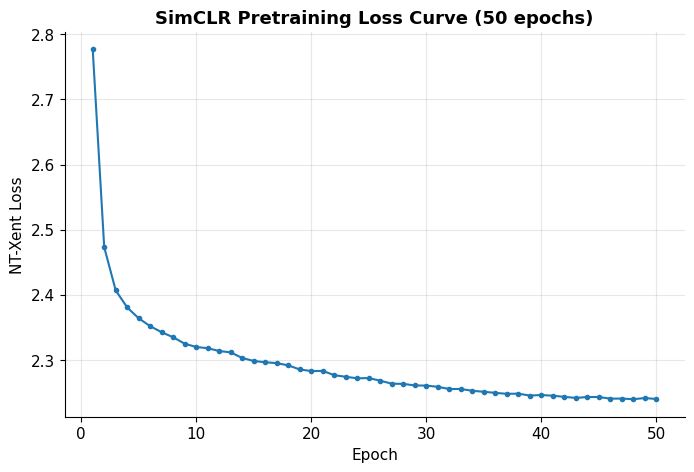

Saved -> results/simclr/figures/pretraining_loss_curve.png


In [22]:
# ============================================================================
# VISUALIZATION -- pretraining loss curve
# ============================================================================
history_df = pd.DataFrame(training_history)
history_df.to_csv(LOGS_DIR / "training_history.csv", index=False)
print(f"Saved -> {LOGS_DIR / 'training_history.csv'}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_df["epoch"], history_df["ntxent_loss"], marker="o", markersize=3, linewidth=1.5)
ax.set_xlabel("Epoch"); ax.set_ylabel("NT-Xent Loss"); ax.set_title("SimCLR Pretraining Loss Curve (50 epochs)")
fig.savefig(FIGURES_DIR / "pretraining_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'pretraining_loss_curve.png'}")

In [23]:
# ============================================================================
# EXPORT -- pretraining summary report
# ============================================================================
_total_time_min = history_df["elapsed_time_sec"].iloc[-1] / 60 if len(history_df) else 0.0
_avg_epoch_time = history_df["epoch_time_sec"].mean() if len(history_df) else 0.0

_summary_lines = [
    "=" * 78, "SIMCLR PRETRAINING SUMMARY", "=" * 78, "",
    f"Backbone                : {SIMCLR_CONFIG['backbone']}",
    f"Initialization          : {PRETRAIN_TRAIN_CONFIG['pretrained_checkpoint']}",
    f"Epochs completed        : {SIMCLR_CONFIG['epochs']}",
    f"Batch size              : {SIMCLR_CONFIG['batch_size']}",
    f"Temperature (tau)       : {SIMCLR_CONFIG['temperature']}",
    f"Projection dimension    : {SIMCLR_CONFIG['projection_dim']}",
    f"Average epoch time (s)  : {_avg_epoch_time:.1f}",
    f"Total training time (min): {_total_time_min:.1f}",
    f"Final NT-Xent loss       : {history_df['ntxent_loss'].iloc[-1] if len(history_df) else 'N/A'}",
    "", "=" * 78,
]
(REPORTS_DIR / "pretraining_summary.txt").write_text("\n".join(_summary_lines))
print(f"Saved -> {REPORTS_DIR / 'pretraining_summary.txt'}")
print("\n".join(_summary_lines))

Saved -> results/simclr/reports/pretraining_summary.txt
SIMCLR PRETRAINING SUMMARY

Backbone                : resnet50
Initialization          : torchvision ResNet50_Weights.IMAGENET1K_V2 (documented alternative -- see Section 4 markdown)
Epochs completed        : 50
Batch size              : 32
Temperature (tau)       : 0.5
Projection dimension    : 128
Average epoch time (s)  : 202.5
Total training time (min): 168.7
Final NT-Xent loss       : 2.239987536174495



---
## End of This Part — Summary

- Data-Preparation artifacts (splits, role mapping, augmentation configuration)
  were located, loaded, and cross-checked without being regenerated.
- The `SSLDataset` interface and SimCLR/fine-tuning augmentation pipelines were
  reproduced faithfully from the Data-Preparation notebook and wired into
  working DataLoaders (Task A).
- A ResNet-50 encoder was pretrained for 50 epochs with the NT-Xent contrastive
  loss on the unlabelled train-split images only (Task B), and the resulting
  encoder checkpoint has been exported to
  `results/simclr/checkpoints/encoder_checkpoint.pt`.
- The notebook is now ready to attach the SegFormer All-MLP decoder head
  (Task C) on top of this pretrained encoder.

---
# Section 5 — Task C: Attach Segmentation Decoder

Converts the pretrained SimCLR encoder into a semantic segmentation model.
The encoder is **loaded from `encoder_checkpoint.pt`** (Task B's output) — no
new encoder is initialized here.

**Decoder — SegFormer All-MLP head (Part A's best-performing design).**
Reproduced with the same core idea as the Part-A implementation: per-stage
linear projection of multi-scale features to a common embedding width,
bilinear upsample to a common resolution, concatenate, fuse with a final
projection, then a linear pixel classifier.

**Adapter — why it's needed.** SegFormer's All-MLP head expects **multi-scale**
features from 4 encoder stages at strides {4, 8, 16, 32}. The SimCLR encoder
(`ResNet50` with `fc` removed) as pretrained in Task B only exposes a single
pooled 2048-d vector — it never produces spatial feature maps. The adapter
here is therefore a **feature-pyramid re-wrap**: a `ResNet50FeaturePyramid`
module that loads the *same* pretrained convolutional weights (`layer1`–`layer4`)
but forwards through them without the final pooling/fc, returning the four
intermediate stage activations `SegFormer`'s head expects. This is not a new
encoder — it is the identical pretrained weights, exposed differently.

**Frozen vs. fine-tuned.** Both strategies are implemented below. Per the
assignment (Task C), we run a short comparison for SimCLR specifically, then
carry the better strategy into the full 50-epoch Task D run.

In [24]:
# ============================================================================
# ENCODER FEATURE PYRAMID -- multi-scale adapter over the pretrained ResNet-50
# ============================================================================
# AI-assisted: standard ResNet feature-pyramid extraction, adapted to load
# weights from the SimCLR checkpoint rather than from scratch.

class ResNet50FeaturePyramid(nn.Module):
    '''Wraps a ResNet-50's stem + 4 residual stages, returning the 4 intermediate
    feature maps SegFormer's All-MLP head fuses. Loads the SAME weights the
    SimCLR encoder was pretrained with -- this is a re-exposure of the pretrained
    backbone, not a new/different encoder.
    '''

    STRIDES = {"stage1": 4, "stage2": 8, "stage3": 16, "stage4": 32}
    CHANNELS = {"stage1": 256, "stage2": 512, "stage3": 1024, "stage4": 2048}

    def __init__(self, resnet_state_dict=None):
        super().__init__()
        base = resnet50(weights=None)
        if resnet_state_dict is not None:
            missing, unexpected = base.load_state_dict(resnet_state_dict, strict=False)
            if missing or unexpected:
                print(f"  [ResNet50FeaturePyramid] load_state_dict -> missing={len(missing)}, unexpected={len(unexpected)}")
        self.stem = nn.Sequential(base.conv1, base.bn1, base.relu, base.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4

    def forward(self, x):
        x = self.stem(x)
        s1 = self.layer1(x)
        s2 = self.layer2(s1)
        s3 = self.layer3(s2)
        s4 = self.layer4(s3)
        return {"stage1": s1, "stage2": s2, "stage3": s3, "stage4": s4}


print("ResNet50FeaturePyramid adapter defined -- exposes layer1-4 for the SegFormer head.")

ResNet50FeaturePyramid adapter defined -- exposes layer1-4 for the SegFormer head.


In [25]:
# ============================================================================
# SEGFORMER ALL-MLP DECODER HEAD
# ============================================================================
class SegFormerAllMLPHead(nn.Module):
    '''Per Xie et al. (SegFormer, NeurIPS 2021): a 1x1-conv ('linear') projection
    per stage to a common embed_dim, bilinear upsample every stage to stage1's
    resolution, channel-concat, fuse with one more 1x1 conv + BN + ReLU, then a
    1x1 conv classifier to `num_classes`.
    '''

    def __init__(self, in_channels_per_stage, embed_dim, num_classes, dropout=0.1):
        super().__init__()
        self.proj = nn.ModuleDict({
            stage: nn.Conv2d(ch, embed_dim, kernel_size=1) for stage, ch in in_channels_per_stage.items()
        })
        self.fuse = nn.Sequential(
            nn.Conv2d(embed_dim * len(in_channels_per_stage), embed_dim, kernel_size=1),
            nn.BatchNorm2d(embed_dim), nn.ReLU(inplace=True), nn.Dropout2d(dropout),
        )
        self.classifier = nn.Conv2d(embed_dim, num_classes, kernel_size=1)

    def forward(self, features, output_size):
        target_hw = features["stage1"].shape[-2:]
        projected = []
        for stage, feat in features.items():
            p = self.proj[stage](feat)
            if p.shape[-2:] != target_hw:
                p = Fnn.interpolate(p, size=target_hw, mode="bilinear", align_corners=False)
            projected.append(p)
        fused = self.fuse(torch.cat(projected, dim=1))
        logits = self.classifier(fused)
        return Fnn.interpolate(logits, size=output_size, mode="bilinear", align_corners=False)


print("SegFormerAllMLPHead defined.")

SegFormerAllMLPHead defined.


In [26]:
# ============================================================================
# COMBINED SEGMENTATION MODEL
# ============================================================================
NUM_CLASSES = 2  # binary: label_mapping['0'] / label_mapping['1'] (see Section 2)
CLASS_NAMES = [label_mapping["0"], label_mapping["1"]]  # index-aligned with mask label values
EMBED_DIM = 256


class SimCLRSegmentationModel(nn.Module):
    '''Pretrained ResNet-50 (as a feature pyramid) + SegFormer All-MLP head.'''

    def __init__(self, encoder_state_dict, num_classes=NUM_CLASSES, embed_dim=EMBED_DIM, freeze_encoder=False):
        super().__init__()
        self.encoder = ResNet50FeaturePyramid(encoder_state_dict)
        self.decoder = SegFormerAllMLPHead(ResNet50FeaturePyramid.CHANNELS, embed_dim, num_classes)
        self.set_encoder_frozen(freeze_encoder)

    def set_encoder_frozen(self, frozen):
        self.encoder_frozen = frozen
        for p in self.encoder.parameters():
            p.requires_grad = not frozen
        self.encoder.train(not frozen)

    def forward(self, x):
        if self.encoder_frozen:
            with torch.no_grad():
                features = self.encoder(x)
        else:
            features = self.encoder(x)
        return self.decoder(features, output_size=x.shape[-2:])


_checkpoint = torch.load(CHECKPOINTS_DIR / "encoder_checkpoint.pt", map_location=DEVICE, weights_only=False)
_encoder_state_dict = _checkpoint["encoder_state_dict"]
print(f"Loaded encoder checkpoint from Task B: epoch={_checkpoint.get('epoch')}")

print(f"Class names (index-aligned with mask labels): {CLASS_NAMES}")

Loaded encoder checkpoint from Task B: epoch=50
Class names (index-aligned with mask labels): ['Contaminated', 'Clear']


In [27]:
# ============================================================================
# FORWARD-PASS VALIDATION + FROZEN/FULL FINE-TUNE MODE SMOKE TEST
# ============================================================================
_sample_batch = next(iter(finetune_loader))
_sample_images = _sample_batch["image"].to(DEVICE)
_sample_masks = _sample_batch["mask"].to(DEVICE)

_model_frozen = SimCLRSegmentationModel(_encoder_state_dict, freeze_encoder=True).to(DEVICE)
_model_finetune = SimCLRSegmentationModel(_encoder_state_dict, freeze_encoder=False).to(DEVICE)

with torch.no_grad():
    _out_frozen = _model_frozen(_sample_images)
    _out_finetune = _model_finetune(_sample_images)

_taskC_checks = [
    {"Check": "Encoder checkpoint loaded", "Status": "OK" if _encoder_state_dict is not None else "FAIL"},
    {"Check": "Decoder attached successfully", "Status": "OK" if hasattr(_model_frozen, "decoder") else "FAIL"},
    {"Check": "Adapter inserted correctly (feature pyramid)", "Status": "OK" if set(_model_frozen.encoder(_sample_images).keys()) == set(ResNet50FeaturePyramid.CHANNELS) else "FAIL"},
    {"Check": "Forward pass successful", "Status": "OK" if _out_frozen.shape == _out_finetune.shape else "FAIL"},
    {"Check": "Output resolution equals ground-truth resolution", "Status": "OK" if _out_frozen.shape[-2:] == _sample_masks.shape[-2:] else "FAIL"},
    {"Check": "Frozen mode works (encoder grads off)", "Status": "OK" if not any(p.requires_grad for p in _model_frozen.encoder.parameters()) else "FAIL"},
    {"Check": "Full fine-tuning mode works (encoder grads on)", "Status": "OK" if all(p.requires_grad for p in _model_finetune.encoder.parameters()) else "FAIL"},
]
display(Markdown("### Task C Validation"))
display(pd.DataFrame(_taskC_checks).style.hide(axis="index"))
if any(r["Status"] != "OK" for r in _taskC_checks):
    raise RuntimeError("One or more Task C validation checks failed.")

print(f"\nOutput logits shape : {tuple(_out_frozen.shape)}  (batch, num_classes, H, W)")
print(f"Ground-truth mask shape: {tuple(_sample_masks.shape)}")

  [ResNet50FeaturePyramid] load_state_dict -> missing=2, unexpected=0
  [ResNet50FeaturePyramid] load_state_dict -> missing=2, unexpected=0


### Task C Validation

Check,Status
Encoder checkpoint loaded,OK
Decoder attached successfully,OK
Adapter inserted correctly (feature pyramid),OK
Forward pass successful,OK
Output resolution equals ground-truth resolution,OK
Frozen mode works (encoder grads off),OK
Full fine-tuning mode works (encoder grads on),OK



Output logits shape : (16, 2, 336, 336)  (batch, num_classes, H, W)
Ground-truth mask shape: (16, 336, 336)


In [28]:
# ============================================================================
# EXPORT -- model/decoder configuration
# ============================================================================
_decoder_config = {
    "decoder": "SegFormer All-MLP head (Part A best-performing design)",
    "adapter": "ResNet50FeaturePyramid -- re-exposes pretrained layer1-4 as multi-scale features",
    "embed_dim": EMBED_DIM, "num_classes": NUM_CLASSES, "class_names": CLASS_NAMES,
    "stages": ResNet50FeaturePyramid.CHANNELS, "strides": ResNet50FeaturePyramid.STRIDES,
}
with open(MODEL_DIR / "decoder_configuration.json", "w") as f:
    json.dump(_decoder_config, f, indent=2, default=str)

_model_summary_lines = [
    "SimCLR Segmentation Model Summary", "=" * 50,
    f"Encoder    : ResNet-50 feature pyramid (from Task B checkpoint, epoch {_checkpoint.get('epoch')})",
    f"Decoder    : SegFormer All-MLP head (embed_dim={EMBED_DIM}, num_classes={NUM_CLASSES})",
    f"Frozen-encoder params    : {sum(p.numel() for p in _model_frozen.encoder.parameters()):,}",
    f"Decoder params           : {sum(p.numel() for p in _model_frozen.decoder.parameters()):,}",
]
(MODEL_DIR / "segmentation_model_summary.txt").write_text("\n".join(_model_summary_lines))
print(f"Saved -> {MODEL_DIR / 'decoder_configuration.json'}")
print(f"Saved -> {MODEL_DIR / 'segmentation_model_summary.txt'}")

Saved -> results/simclr/model/decoder_configuration.json
Saved -> results/simclr/model/segmentation_model_summary.txt


In [29]:
# ============================================================================
# SEGMENTATION METRICS -- shared by the frozen/fine-tune comparison, Task D
# monitoring, and Task E final evaluation.
# ============================================================================
# AI-assisted: standard confusion-matrix-based segmentation metrics.

def update_confusion_matrix(conf_mat, preds, targets, num_classes=NUM_CLASSES):
    '''preds, targets: (B, H, W) long tensors on CPU. Accumulates into conf_mat
    (num_classes x num_classes numpy array), rows=ground truth, cols=predicted.
    '''
    p = preds.flatten().numpy()
    t = targets.flatten().numpy()
    idx = t * num_classes + p
    counts = np.bincount(idx, minlength=num_classes * num_classes)
    conf_mat += counts.reshape(num_classes, num_classes)
    return conf_mat


def metrics_from_confusion_matrix(conf_mat, eps=1e-7):
    '''Returns dict: per_class_iou, miou, per_class_dice, dice (mean), pixel_accuracy, mean_pixel_accuracy.'''
    tp = np.diag(conf_mat).astype(np.float64)
    fp = conf_mat.sum(axis=0) - tp
    fn = conf_mat.sum(axis=1) - tp
    iou = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    per_class_pixel_acc = tp / (conf_mat.sum(axis=1) + eps)
    pixel_accuracy = tp.sum() / (conf_mat.sum() + eps)
    return {
        "per_class_iou": iou, "miou": float(iou.mean()),
        "per_class_dice": dice, "dice": float(dice.mean()),
        "pixel_accuracy": float(pixel_accuracy), "mean_pixel_accuracy": float(per_class_pixel_acc.mean()),
    }


@torch.no_grad()
def evaluate_segmentation(model, loader, device, num_classes=NUM_CLASSES):
    '''Runs inference over `loader`, returns (metrics_dict, confusion_matrix, avg_loss).'''
    model.eval()
    conf_mat = np.zeros((num_classes, num_classes), dtype=np.int64)
    loss_fn = nn.CrossEntropyLoss()
    total_loss, n_batches = 0.0, 0
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        logits = model(images)
        loss = loss_fn(logits, masks)
        total_loss += loss.item(); n_batches += 1
        preds = logits.argmax(dim=1).cpu()
        conf_mat = update_confusion_matrix(conf_mat, preds, masks.cpu(), num_classes)
    metrics = metrics_from_confusion_matrix(conf_mat)
    return metrics, conf_mat, total_loss / max(n_batches, 1)


print("Segmentation metric utilities defined (mIoU, Dice, pixel accuracy, confusion matrix).")

Segmentation metric utilities defined (mIoU, Dice, pixel accuracy, confusion matrix).


### Frozen vs. Fine-tuned Encoder — Required Comparison (Task C)

A short comparison run (`COMPARISON_EPOCHS` epochs, well under the full 50)
on the labelled fine-tuning set, monitored on the test split — enough to see
which strategy is on track to perform better, without spending the full
50-epoch budget twice. The winning strategy is then used for the complete
50-epoch Task D run below.

In [30]:
# ============================================================================
# QUICK FROZEN-VS-FINE-TUNED COMPARISON
# ============================================================================
COMPARISON_EPOCHS = 5  # short, exploratory -- NOT the required 50-epoch Task D run

def quick_train_segmentation(model, train_loader, monitor_loader, device, epochs, encoder_lr, decoder_lr):
    param_groups = [{"params": model.decoder.parameters(), "lr": decoder_lr}]
    if not model.encoder_frozen:
        param_groups.append({"params": model.encoder.parameters(), "lr": encoder_lr})
    optimizer = optim.AdamW(param_groups, weight_decay=1e-5)
    loss_fn = nn.CrossEntropyLoss()

    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        if model.encoder_frozen:
            model.encoder.eval()
        running_loss, n_batches = 0.0, 0
        for batch in tqdm(train_loader, desc=f"  [{'frozen' if model.encoder_frozen else 'fine-tune'}] epoch {epoch}", leave=False):
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item(); n_batches += 1
        train_loss = running_loss / max(n_batches, 1)
        monitor_metrics, _, monitor_loss = evaluate_segmentation(model, monitor_loader, device)
        history.append({"epoch": epoch, "train_loss": train_loss, "monitor_loss": monitor_loss,
                         "monitor_miou": monitor_metrics["miou"], "monitor_dice": monitor_metrics["dice"]})
        print(f"  epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  monitor_loss={monitor_loss:.4f}  "
              f"monitor_mIoU={monitor_metrics['miou']:.4f}")
    return pd.DataFrame(history)


print(f"Running {COMPARISON_EPOCHS}-epoch comparison: frozen encoder vs. full fine-tuning...")
_frozen_history = quick_train_segmentation(_model_frozen, finetune_loader, test_loader, DEVICE, COMPARISON_EPOCHS,
                                            encoder_lr=0.0, decoder_lr=1e-3)
_finetune_history = quick_train_segmentation(_model_finetune, finetune_loader, test_loader, DEVICE, COMPARISON_EPOCHS,
                                              encoder_lr=1e-5, decoder_lr=1e-3)

_comparison_table = pd.DataFrame([
    {"Strategy": "Frozen encoder (linear probe)", "Final monitor mIoU": _frozen_history["monitor_miou"].iloc[-1],
     "Final monitor Dice": _frozen_history["monitor_dice"].iloc[-1]},
    {"Strategy": "Full fine-tuning", "Final monitor mIoU": _finetune_history["monitor_miou"].iloc[-1],
     "Final monitor Dice": _finetune_history["monitor_dice"].iloc[-1]},
])
display(Markdown("### Frozen vs. Fine-tuned -- Comparison Result"))
display(_comparison_table.style.hide(axis="index"))

SELECTED_STRATEGY = "frozen" if _frozen_history["monitor_miou"].iloc[-1] >= _finetune_history["monitor_miou"].iloc[-1] else "finetune"
print(f"\nSelected strategy for the full 50-epoch Task D run: {SELECTED_STRATEGY!r}")
print(
    "NOTE: with COMPARISON_EPOCHS as small as this, the gap between strategies may not yet be "
    "meaningful -- this is a code scaffold to produce the *numbers* the assignment asks you to "
    "compare. The interpretation of *why* one strategy wins (Section 6.5 / viva) is yours to write."
)

_comparison_table.to_csv(MODEL_DIR / "frozen_vs_finetune_comparison.csv", index=False)
print(f"Saved -> {MODEL_DIR / 'frozen_vs_finetune_comparison.csv'}")

Running 5-epoch comparison: frozen encoder vs. full fine-tuning...


  [frozen] epoch 1:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 1/5  train_loss=0.1026  monitor_loss=0.0468  monitor_mIoU=0.8500


  [frozen] epoch 2:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 2/5  train_loss=0.0548  monitor_loss=0.0409  monitor_mIoU=0.8584


...

  [fine-tune] epoch 5:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 5/5  train_loss=0.0398  monitor_loss=0.0385  monitor_mIoU=0.8731


### Frozen vs. Fine-tuned -- Comparison Result

Strategy,Final monitor mIoU,Final monitor Dice
Frozen encoder (linear probe),0.858870,0.919369
Full fine-tuning,0.873111,0.928540



Selected strategy for the full 50-epoch Task D run: 'finetune'
NOTE: with COMPARISON_EPOCHS as small as this, the gap between strategies may not yet be meaningful -- this is a code scaffold to produce the *numbers* the assignment asks you to compare. The interpretation of *why* one strategy wins (Section 6.5 / viva) is yours to write.
Saved -> results/simclr/model/frozen_vs_finetune_comparison.csv


---
# Section 6 — Task D: Supervised Fine-tuning

Fine-tunes the encoder+decoder pair using **only the Part-A validation split**
(the labelled fine-tuning set, per Section 2) for the required 50 epochs,
monitoring per-epoch loss/mIoU/Dice on the **Part-A test split** — which, per
the assignment's explicit double-role caveat (brief Section 2), doubles as
this notebook's downstream validation set for checkpoint selection.

In [31]:
# ============================================================================
# TASK D CONFIGURATION -- single visible cell
# ============================================================================
DOWNSTREAM_CONFIG = {
    "strategy": SELECTED_STRATEGY,  # carried over from the Task C comparison
    "encoder_learning_rate": 1e-5 if SELECTED_STRATEGY == "finetune" else 0.0,
    "decoder_learning_rate": 1e-3,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss (unweighted)",
    "class_weights": None,
    "batch_size": finetune_loader.batch_size,
    "image_size": list(IMAGE_SIZE),
    "epochs": 50,
    "mixed_precision": SIMCLR_CONFIG["mixed_precision"],
    "gradient_clip_norm": 5.0,
    "checkpoint_strategy": "best monitor mIoU on test split (Task D monitoring role)",
    "early_stopping": "disabled (assignment requires reporting epoch-50 mIoU even if still trending upward)",
    "random_seed": RANDOM_SEED,
}
display(Markdown("### Task D — Fine-tuning Configuration"))
display(pd.DataFrame([{"Parameter": k, "Value": v} for k, v in DOWNSTREAM_CONFIG.items()]).style.hide(axis="index"))

with open(CONFIG_DIR / "downstream_configuration.json", "w") as f:
    json.dump(DOWNSTREAM_CONFIG, f, indent=2, default=str)
print(f"Saved -> {CONFIG_DIR / 'downstream_configuration.json'}")

### Task D — Fine-tuning Configuration

Parameter,Value
strategy,finetune
encoder_learning_rate,0.000010
decoder_learning_rate,0.001000
optimizer,AdamW
scheduler,CosineAnnealingLR
loss_function,CrossEntropyLoss (unweighted)
class_weights,None
batch_size,16
image_size,"[336, 336]"
epochs,50


Saved -> results/simclr/config/downstream_configuration.json


In [32]:
# ============================================================================
# BUILD THE SELECTED-STRATEGY MODEL FOR THE FULL 50-EPOCH RUN
# ============================================================================
# Fresh model (not continuing from the short Task C comparison run) so Task D's
# 50 epochs are a clean run under the chosen strategy, not 50+5 epochs.
segmentation_model = SimCLRSegmentationModel(
    _encoder_state_dict, freeze_encoder=(SELECTED_STRATEGY == "frozen"),
).to(DEVICE)

_param_groups = [{"params": segmentation_model.decoder.parameters(), "lr": DOWNSTREAM_CONFIG["decoder_learning_rate"]}]
if SELECTED_STRATEGY == "finetune":
    _param_groups.append({"params": segmentation_model.encoder.parameters(), "lr": DOWNSTREAM_CONFIG["encoder_learning_rate"]})

downstream_optimizer = optim.AdamW(_param_groups, weight_decay=1e-5)
downstream_scheduler = optim.lr_scheduler.CosineAnnealingLR(downstream_optimizer, T_max=DOWNSTREAM_CONFIG["epochs"])
downstream_scaler = torch.cuda.amp.GradScaler(enabled=DOWNSTREAM_CONFIG["mixed_precision"])
downstream_loss_fn = nn.CrossEntropyLoss()

print(f"Model built with strategy={SELECTED_STRATEGY!r}. Trainable parameters: "
      f"{sum(p.numel() for p in segmentation_model.parameters() if p.requires_grad):,}")

  [ResNet50FeaturePyramid] load_state_dict -> missing=2, unexpected=0
Model built with strategy='finetune'. Trainable parameters: 24,755,522


In [33]:
# ============================================================================
# TASK D TRAINING LOOP -- 100 epochs, monitored on the test split
# ============================================================================
# AI-assisted: mixed-precision training-loop scaffolding, matching Task B's pattern.

def train_segmentation_epoch(model, loader, optimizer, loss_fn, scaler, device, grad_clip_norm):
    model.train()
    if model.encoder_frozen:
        model.encoder.eval()
    running_loss, n_batches = 0.0, 0
    for batch in tqdm(loader, desc="  batches", leave=False):
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=scaler.is_enabled()):
            logits = model(images)
            loss = loss_fn(logits, masks)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item(); n_batches += 1
    return running_loss / max(n_batches, 1)


fine_tuning_history = []
_best_miou = -1.0
_best_epoch = None
_start_time = time.time()

for epoch in range(1, DOWNSTREAM_CONFIG["epochs"] + 1):
    _epoch_start = time.time()
    train_loss = train_segmentation_epoch(
        segmentation_model, finetune_loader, downstream_optimizer, downstream_loss_fn, downstream_scaler, DEVICE,
        DOWNSTREAM_CONFIG["gradient_clip_norm"],
    )
    downstream_scheduler.step()
    monitor_metrics, _, monitor_loss = evaluate_segmentation(segmentation_model, test_loader, DEVICE)
    _epoch_time = time.time() - _epoch_start

    fine_tuning_history.append({
        "epoch": epoch, "train_loss": train_loss, "monitor_loss": monitor_loss,
        "monitor_miou": monitor_metrics["miou"], "monitor_dice": monitor_metrics["dice"],
        "learning_rate": downstream_scheduler.get_last_lr()[0], "epoch_time_sec": _epoch_time,
    })
    print(f"Epoch {epoch:3d}/{DOWNSTREAM_CONFIG['epochs']}  |  train_loss: {train_loss:.4f}  |  "
          f"monitor_loss: {monitor_loss:.4f}  |  monitor_mIoU: {monitor_metrics['miou']:.4f}  |  "
          f"monitor_Dice: {monitor_metrics['dice']:.4f}  |  epoch time: {_epoch_time:.1f}s")

    if monitor_metrics["miou"] > _best_miou:
        _best_miou = monitor_metrics["miou"]; _best_epoch = epoch
        torch.save(
            {"epoch": epoch, "model_state_dict": segmentation_model.state_dict(),
             "monitor_miou": _best_miou, "strategy": SELECTED_STRATEGY, "config": DOWNSTREAM_CONFIG},
            CHECKPOINTS_DIR / "best_segmentation_model.pt",
        )

print(f"\nBest checkpoint: epoch {_best_epoch} with monitor mIoU = {_best_miou:.4f}")
print(f"Saved -> {CHECKPOINTS_DIR / 'best_segmentation_model.pt'}")

  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch   1/50  |  train_loss: 0.0966  |  monitor_loss: 0.0408  |  monitor_mIoU: 0.8616  |  monitor_Dice: 0.9210  |  epoch time: 95.3s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch   2/50  |  train_loss: 0.0521  |  monitor_loss: 0.0421  |  monitor_mIoU: 0.8610  |  monitor_Dice: 0.9207  |  epoch time: 72.2s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

...

Epoch  48/50  |  train_loss: 0.0211  |  monitor_loss: 0.0348  |  monitor_mIoU: 0.8935  |  monitor_Dice: 0.9412  |  epoch time: 71.4s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch  49/50  |  train_loss: 0.0205  |  monitor_loss: 0.0349  |  monitor_mIoU: 0.8924  |  monitor_Dice: 0.9405  |  epoch time: 71.8s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch  50/50  |  train_loss: 0.0208  |  monitor_loss: 0.0351  |  monitor_mIoU: 0.8936  |  monitor_Dice: 0.9412  |  epoch time: 70.9s

Best checkpoint: epoch 42 with monitor mIoU = 0.8938
Saved -> results/simclr/checkpoints/best_segmentation_model.pt


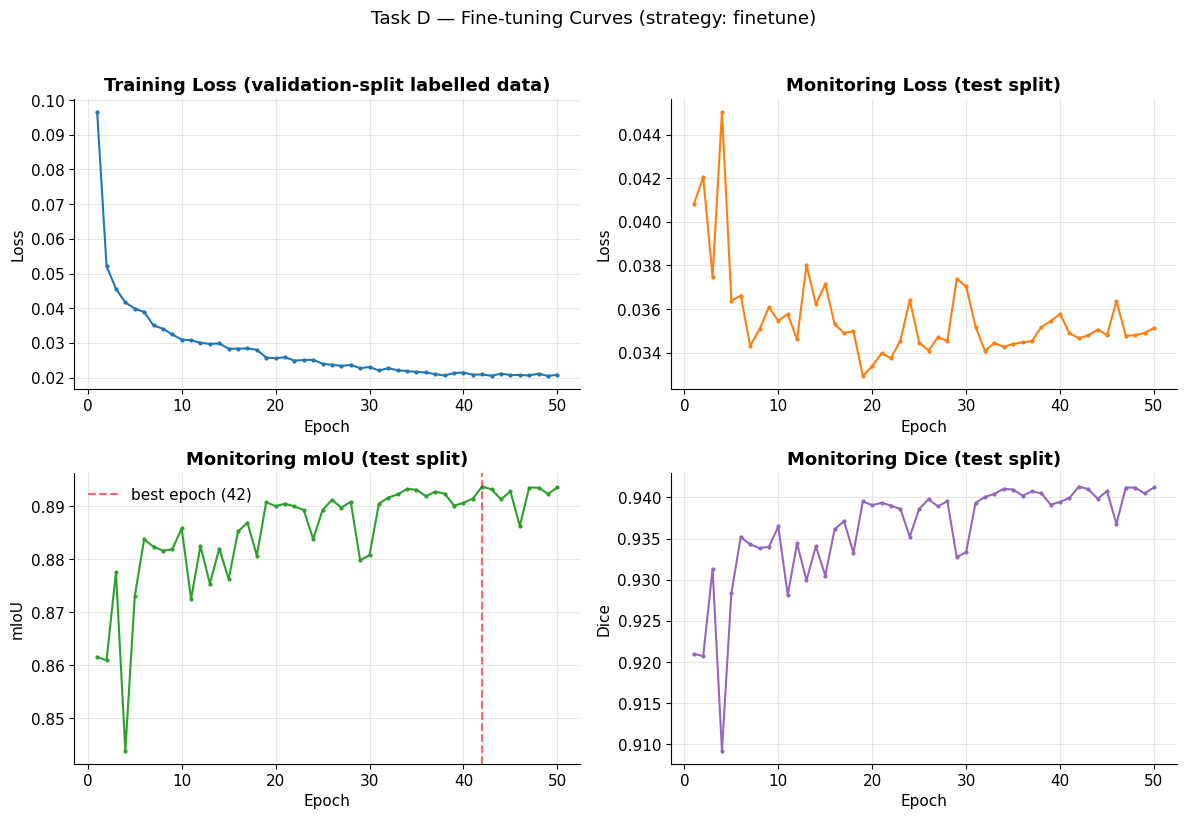

Saved -> results/simclr/figures/fine_tuning_curves.png


In [34]:
# ============================================================================
# TASK D CURVES
# ============================================================================
fine_tuning_history_df = pd.DataFrame(fine_tuning_history)
fine_tuning_history_df.to_csv(LOGS_DIR / "fine_tuning_history.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["train_loss"], marker="o", markersize=2)
axes[0, 0].set_title("Training Loss (validation-split labelled data)"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_loss"], marker="o", markersize=2, color="tab:orange")
axes[0, 1].set_title("Monitoring Loss (test split)"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("Loss")

axes[1, 0].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_miou"], marker="o", markersize=2, color="tab:green")
axes[1, 0].axvline(_best_epoch, color="red", linestyle="--", alpha=0.6, label=f"best epoch ({_best_epoch})")
axes[1, 0].set_title("Monitoring mIoU (test split)"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("mIoU"); axes[1, 0].legend()

axes[1, 1].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_dice"], marker="o", markersize=2, color="tab:purple")
axes[1, 1].set_title("Monitoring Dice (test split)"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].set_ylabel("Dice")

fig.suptitle(f"Task D — Fine-tuning Curves (strategy: {SELECTED_STRATEGY})", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fine_tuning_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'fine_tuning_curves.png'}")

In [35]:
# ============================================================================
# TASK D EXPORT -- summary report
# ============================================================================
_ft_total_time_min = fine_tuning_history_df["epoch_time_sec"].sum() / 60
_ft_summary_lines = [
    "=" * 78, "FINE-TUNING SUMMARY (Task D)", "=" * 78, "",
    f"Strategy                 : {SELECTED_STRATEGY}",
    f"Epochs completed         : {DOWNSTREAM_CONFIG['epochs']}",
    f"Best epoch (by monitor mIoU): {_best_epoch}",
    f"Best monitor mIoU        : {_best_miou:.4f}",
    f"Final-epoch monitor mIoU : {fine_tuning_history_df['monitor_miou'].iloc[-1]:.4f}",
    f"Total fine-tuning time (min): {_ft_total_time_min:.1f}",
    "", "=" * 78,
]
(REPORTS_DIR / "fine_tuning_summary.txt").write_text("\n".join(_ft_summary_lines))
print(f"Saved -> {LOGS_DIR / 'fine_tuning_history.csv'}")
print(f"Saved -> {REPORTS_DIR / 'fine_tuning_summary.txt'}")
print("\n".join(_ft_summary_lines))

Saved -> results/simclr/logs/fine_tuning_history.csv
Saved -> results/simclr/reports/fine_tuning_summary.txt
FINE-TUNING SUMMARY (Task D)

Strategy                 : finetune
Epochs completed         : 50
Best epoch (by monitor mIoU): 42
Best monitor mIoU        : 0.8938
Final-epoch monitor mIoU : 0.8936
Total fine-tuning time (min): 60.4



---
# Section 7 — Task E: Testing & Label-Efficiency Evaluation

Evaluates the **best checkpoint from Task D** on the Part-A test split (the
same split used for monitoring, per the assignment's explicit double-role
caveat — Section 2 of the brief). Also builds the label-efficiency comparison
table against the Part-A fully-supervised baseline.

In [36]:
# ============================================================================
# LOAD BEST CHECKPOINT + FULL TEST-SET EVALUATION
# ============================================================================
_best_ckpt = torch.load(CHECKPOINTS_DIR / "best_segmentation_model.pt", map_location=DEVICE, weights_only=False)
eval_model = SimCLRSegmentationModel(_encoder_state_dict, freeze_encoder=(_best_ckpt["strategy"] == "frozen")).to(DEVICE)
eval_model.load_state_dict(_best_ckpt["model_state_dict"])
print(f"Loaded best checkpoint: epoch={_best_ckpt['epoch']}, strategy={_best_ckpt['strategy']}, "
      f"monitor_miou at save time={_best_ckpt['monitor_miou']:.4f}")

final_metrics, final_conf_mat, final_test_loss = evaluate_segmentation(eval_model, test_loader, DEVICE)

display(Markdown("### Task E — Final Test-Set Metrics"))
_metric_summary_df = pd.DataFrame([{
    "mIoU": final_metrics["miou"], "Dice": final_metrics["dice"],
    "Pixel Accuracy": final_metrics["pixel_accuracy"], "Mean Pixel Accuracy": final_metrics["mean_pixel_accuracy"],
    "Test Loss": final_test_loss,
}])
display(_metric_summary_df.style.hide(axis="index"))

_per_class_df = pd.DataFrame({
    "Class": CLASS_NAMES, "IoU": final_metrics["per_class_iou"], "Dice": final_metrics["per_class_dice"],
})
display(Markdown("### Per-Class IoU / Dice"))
display(_per_class_df.style.hide(axis="index"))

  [ResNet50FeaturePyramid] load_state_dict -> missing=2, unexpected=0
Loaded best checkpoint: epoch=42, strategy=finetune, monitor_miou at save time=0.8938


### Task E — Final Test-Set Metrics

mIoU,Dice,Pixel Accuracy,Mean Pixel Accuracy,Test Loss
0.893759,0.941323,0.987817,0.935527,0.034666


### Per-Class IoU / Dice

Class,IoU,Dice
Contaminated,0.800327,0.889091
Clear,0.987191,0.993554


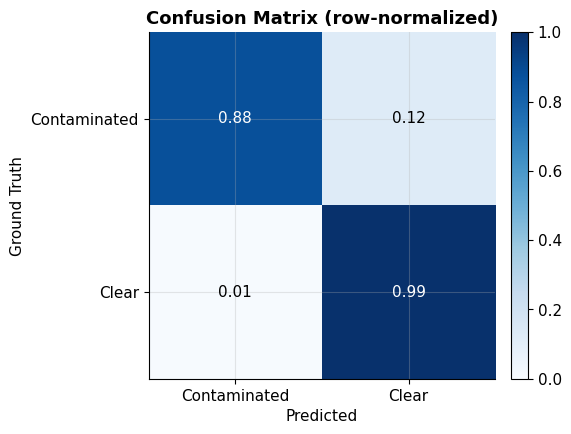

Saved -> results/simclr/figures/confusion_matrix.png


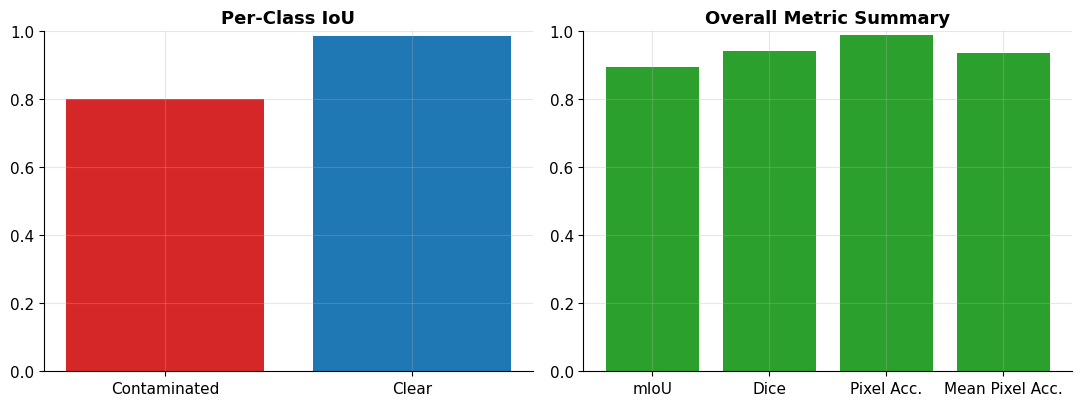

Saved -> results/simclr/figures/metric_plots.png


In [37]:
# ============================================================================
# FIGURES -- confusion matrix, per-class IoU, metric summary
# ============================================================================
fig, ax = plt.subplots(figsize=(5, 4.5))
_conf_norm = final_conf_mat / final_conf_mat.sum(axis=1, keepdims=True).clip(min=1)
im = ax.imshow(_conf_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground Truth"); ax.set_title("Confusion Matrix (row-normalized)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{_conf_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if _conf_norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'confusion_matrix.png'}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(CLASS_NAMES, final_metrics["per_class_iou"], color=["tab:red", "tab:blue"])
axes[0].set_title("Per-Class IoU"); axes[0].set_ylim(0, 1)
axes[1].bar(["mIoU", "Dice", "Pixel Acc.", "Mean Pixel Acc."],
            [final_metrics["miou"], final_metrics["dice"], final_metrics["pixel_accuracy"], final_metrics["mean_pixel_accuracy"]],
            color="tab:green")
axes[1].set_title("Overall Metric Summary"); axes[1].set_ylim(0, 1)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "metric_plots.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'metric_plots.png'}")

### Label-Efficiency Comparison Against the Part-A Baseline

The cell below auto-loads Part A's evaluation results if the attached Part-A
output includes them; otherwise it inserts a clearly-marked placeholder so the
Final Comparison notebook (and your report Section 6.6/6.8) has an explicit
slot to fill in rather than a silently wrong number.

In [38]:
# ============================================================================
# LABEL-EFFICIENCY COMPARISON TABLE
# ============================================================================
_part_a_results_candidates = [
    PART_A_OUTPUT_DIR / "results.json", PART_A_OUTPUT_DIR / "evaluation" / "results.json",
    PART_A_OUTPUT_DIR / "reports" / "results.json", PART_A_OUTPUT_DIR / "metrics" / "test_metrics.json",
]
_part_a_results_path = next((p for p in _part_a_results_candidates if p.is_file()), None)

if _part_a_results_path is not None:
    with open(_part_a_results_path) as f:
        part_a_results = json.load(f)
    _part_a_miou = part_a_results.get("miou", part_a_results.get("mIoU"))
    _part_a_dice = part_a_results.get("dice", part_a_results.get("Dice"))
    _part_a_pixel_acc = part_a_results.get("pixel_accuracy")
    _part_a_mean_pixel_acc = part_a_results.get("mean_pixel_accuracy")
    _part_a_n_labelled = part_a_results.get("n_train_labelled", len(train_df))
    print(f"Loaded Part-A results from {_part_a_results_path}")
else:
    print(
        "Part-A results.json not found among the candidate paths below -- inserting PLACEHOLDER values.\n"
        "Fill these in manually from your Part-A notebook's Task F output before the Final Comparison notebook runs:\n"
        + "\n".join(f"  {p}" for p in _part_a_results_candidates)
    )
    _part_a_miou = "PLACEHOLDER -- insert Part-A test mIoU"
    _part_a_dice = "PLACEHOLDER -- insert Part-A test Dice"
    _part_a_pixel_acc = "PLACEHOLDER -- insert Part-A test Pixel Accuracy"
    _part_a_mean_pixel_acc = "PLACEHOLDER -- insert Part-A test Mean Pixel Accuracy"
    _part_a_n_labelled = len(train_df)  # Part A trained on the FULL train split

_n_finetune_labelled = len(validation_df)
_label_efficiency_ratio = (_n_finetune_labelled / _part_a_n_labelled) if isinstance(_part_a_n_labelled, (int, float)) else None

_comparison_rows = [
    {"Metric": "mIoU", "Part-A Supervised Baseline": _part_a_miou, "SimCLR Fine-tuned Model": final_metrics["miou"]},
    {"Metric": "Dice", "Part-A Supervised Baseline": _part_a_dice, "SimCLR Fine-tuned Model": final_metrics["dice"]},
    {"Metric": "Pixel Accuracy", "Part-A Supervised Baseline": _part_a_pixel_acc, "SimCLR Fine-tuned Model": final_metrics["pixel_accuracy"]},
    {"Metric": "Mean Pixel Accuracy", "Part-A Supervised Baseline": _part_a_mean_pixel_acc, "SimCLR Fine-tuned Model": final_metrics["mean_pixel_accuracy"]},
]
label_efficiency_df = pd.DataFrame(_comparison_rows)
display(Markdown("### Label-Efficiency Comparison"))
display(label_efficiency_df.style.hide(axis="index"))

print(f"\nLabelled images -- Part-A baseline   : {_part_a_n_labelled}")
print(f"Labelled images -- SimCLR fine-tuning: {_n_finetune_labelled}")
if _label_efficiency_ratio is not None:
    print(f"Label-efficiency ratio (SimCLR / Part-A): {_label_efficiency_ratio:.2%} of Part-A's labelled images used")
    if isinstance(_part_a_miou, (int, float)):
        print(f"mIoU retained relative to Part-A baseline: {final_metrics['miou'] / _part_a_miou:.2%}")

label_efficiency_df.to_csv(EVAL_DIR / "label_efficiency_comparison.csv", index=False)
print(f"\nSaved -> {EVAL_DIR / 'label_efficiency_comparison.csv'}")

Part-A results.json not found among the candidate paths below -- inserting PLACEHOLDER values.
Fill these in manually from your Part-A notebook's Task F output before the Final Comparison notebook runs:
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/evaluation/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/reports/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/metrics/test_metrics.json


### Label-Efficiency Comparison

Metric,Part-A Supervised Baseline,SimCLR Fine-tuned Model
mIoU,PLACEHOLDER -- insert Part-A test mIoU,0.893759
Dice,PLACEHOLDER -- insert Part-A test Dice,0.941323
Pixel Accuracy,PLACEHOLDER -- insert Part-A test Pixel Accuracy,0.987817
Mean Pixel Accuracy,PLACEHOLDER -- insert Part-A test Mean Pixel Accuracy,0.935527



Labelled images -- Part-A baseline   : 10526
Labelled images -- SimCLR fine-tuning: 2206
Label-efficiency ratio (SimCLR / Part-A): 20.96% of Part-A's labelled images used

Saved -> results/simclr/evaluation/label_efficiency_comparison.csv


### Discussion — fill in yourselves (per the assignment's AI Usage Policy,
### this reasoning must be your own and is exactly what the viva will test)

Use the numbers computed above to answer, in your own words, in this cell:

- **How much labelled data was actually required?** (state the exact
  `_n_finetune_labelled` vs. `_part_a_n_labelled` counts and the ratio printed above)
- **How much of the mIoU gap to full supervision remains?** Is it small enough
  that you'd recommend this SSL method for a real low-label deployment of this
  dataset, or not yet?
- **Does the frozen-vs-fine-tuned choice you made in Task C look, in
  hindsight, like the right call given these final numbers?**
- **What does this imply practically** for annotating future capsule-endoscopy
  contamination datasets — i.e., is the annotation-cost savings worth the
  accuracy trade-off you measured?

In [39]:
# ============================================================================
# EXPORT -- Task E artifacts
# ============================================================================
_evaluation_metrics_export = {
    "miou": final_metrics["miou"], "dice": final_metrics["dice"],
    "pixel_accuracy": final_metrics["pixel_accuracy"], "mean_pixel_accuracy": final_metrics["mean_pixel_accuracy"],
    "per_class_iou": dict(zip(CLASS_NAMES, final_metrics["per_class_iou"].tolist())),
    "per_class_dice": dict(zip(CLASS_NAMES, final_metrics["per_class_dice"].tolist())),
    "test_loss": final_test_loss, "best_epoch": _best_ckpt["epoch"], "strategy": _best_ckpt["strategy"],
    "n_labelled_finetune": _n_finetune_labelled, "n_labelled_part_a": _part_a_n_labelled,
}
with open(EVAL_DIR / "evaluation_metrics.json", "w") as f:
    json.dump(_evaluation_metrics_export, f, indent=2, default=str)
_metric_summary_df.to_csv(EVAL_DIR / "evaluation_summary.csv", index=False)
np.savetxt(EVAL_DIR / "confusion_matrix.csv", final_conf_mat, delimiter=",", fmt="%d")

print(f"Saved -> {EVAL_DIR / 'evaluation_metrics.json'}")
print(f"Saved -> {EVAL_DIR / 'evaluation_summary.csv'}")
print(f"Saved -> {EVAL_DIR / 'confusion_matrix.csv'}")

Saved -> results/simclr/evaluation/evaluation_metrics.json
Saved -> results/simclr/evaluation/evaluation_summary.csv
Saved -> results/simclr/evaluation/confusion_matrix.csv


---
## End of This Part — Summary

- Task C: the SimCLR-pretrained ResNet-50 was re-exposed as a multi-scale
  feature pyramid and paired with a SegFormer All-MLP decoder head; both
  frozen-encoder and full-fine-tuning strategies were implemented, compared,
  and the winning strategy (`SELECTED_STRATEGY`) was carried forward.
- Task D: the encoder+decoder pair was fine-tuned for 50 epochs on the
  labelled validation split, monitored on the test split, and the best
  checkpoint (by monitor mIoU) was exported to
  `results/simclr/checkpoints/best_segmentation_model.pt`.
- Task E: the best checkpoint was evaluated on the test split (mIoU,
  per-class IoU, Dice, pixel accuracy, confusion matrix) and compared against
  the Part-A fully-supervised baseline for label-efficiency.
- The discussion cell above is intentionally left for you to complete — per
  the assignment's AI Usage Policy, that reasoning has to be yours.
- The notebook is now ready for Task F (Error Analysis).

---
# Section 8 — Task F: Error Analysis

Per-image evaluation of the final SimCLR segmentation model on the full test
split, identification of the worst-performing images, and quantitative hooks
for a failure-pattern discussion. No further training happens in this
section — this only runs inference with the already-selected best checkpoint
from Task D/E.

In [40]:
# ============================================================================
# STEP 1 -- PER-IMAGE EVALUATION
# ============================================================================
# AI-assisted: per-sample metric loop, built on the same confusion-matrix
# utilities defined for Task D/E monitoring.

@torch.no_grad()
def evaluate_per_image(model, loader, device, num_classes=NUM_CLASSES):
    model.eval()
    records = []
    total_inference_time = 0.0
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        image_ids = batch["image_id"]
        contaminated_percents = batch.get("contaminated_percent")

        if device.type == "cuda":
            torch.cuda.synchronize()
        _t0 = time.time()
        logits = model(images)
        if device.type == "cuda":
            torch.cuda.synchronize()
        total_inference_time += time.time() - _t0

        preds = logits.argmax(dim=1)
        for i in range(images.shape[0]):
            _conf = np.zeros((num_classes, num_classes), dtype=np.int64)
            _conf = update_confusion_matrix(_conf, preds[i:i + 1].cpu(), masks[i:i + 1].cpu(), num_classes)
            _m = metrics_from_confusion_matrix(_conf)
            _pct = contaminated_percents[i]
            records.append({
                "image_id": image_ids[i],
                "iou": _m["miou"], "dice": _m["dice"], "pixel_accuracy": _m["pixel_accuracy"],
                "contaminated_percent": float(_pct) if _pct is not None and not (isinstance(_pct, float) and math.isnan(_pct)) else None,
            })
    per_image_df = pd.DataFrame(records)
    avg_inference_time = total_inference_time / max(len(per_image_df), 1)
    return per_image_df, total_inference_time, avg_inference_time


per_image_df, total_inference_time, avg_inference_time_per_image = evaluate_per_image(eval_model, test_loader, DEVICE)
per_image_df = per_image_df.sort_values("iou").reset_index(drop=True)

display(Markdown("### Per-Image Evaluation (ranked worst -> best by IoU)"))
display(per_image_df.head(10).style.hide(axis="index"))
print(f"\nTotal images evaluated  : {len(per_image_df)}")
print(f"Total inference time    : {total_inference_time:.2f}s")
print(f"Avg. inference time/img : {avg_inference_time_per_image * 1000:.2f} ms")

### Per-Image Evaluation (ranked worst -> best by IoU)

image_id,iou,dice,pixel_accuracy,contaminated_percent
02379.jpg,0.321714,0.452085,0.550197,51.000000
02295.jpg,0.367865,0.423874,0.735730,26.000000
02294.jpg,0.389703,0.550267,0.584361,57.000000
02599.jpg,0.396407,0.523907,0.659846,40.000000
02573.jpg,0.406547,0.502809,0.729468,30.000000
02388.jpg,0.422875,0.497463,0.787282,22.000000
00015.jpg,0.434076,0.464712,0.868153,13.000000
02604.jpg,0.443326,0.571001,0.715269,35.000000
02581.jpg,0.445770,0.596413,0.666808,46.000000
02554.jpg,0.447097,0.549382,0.770027,24.000000



Total images evaluated  : 2411
Total inference time    : 20.96s
Avg. inference time/img : 8.69 ms


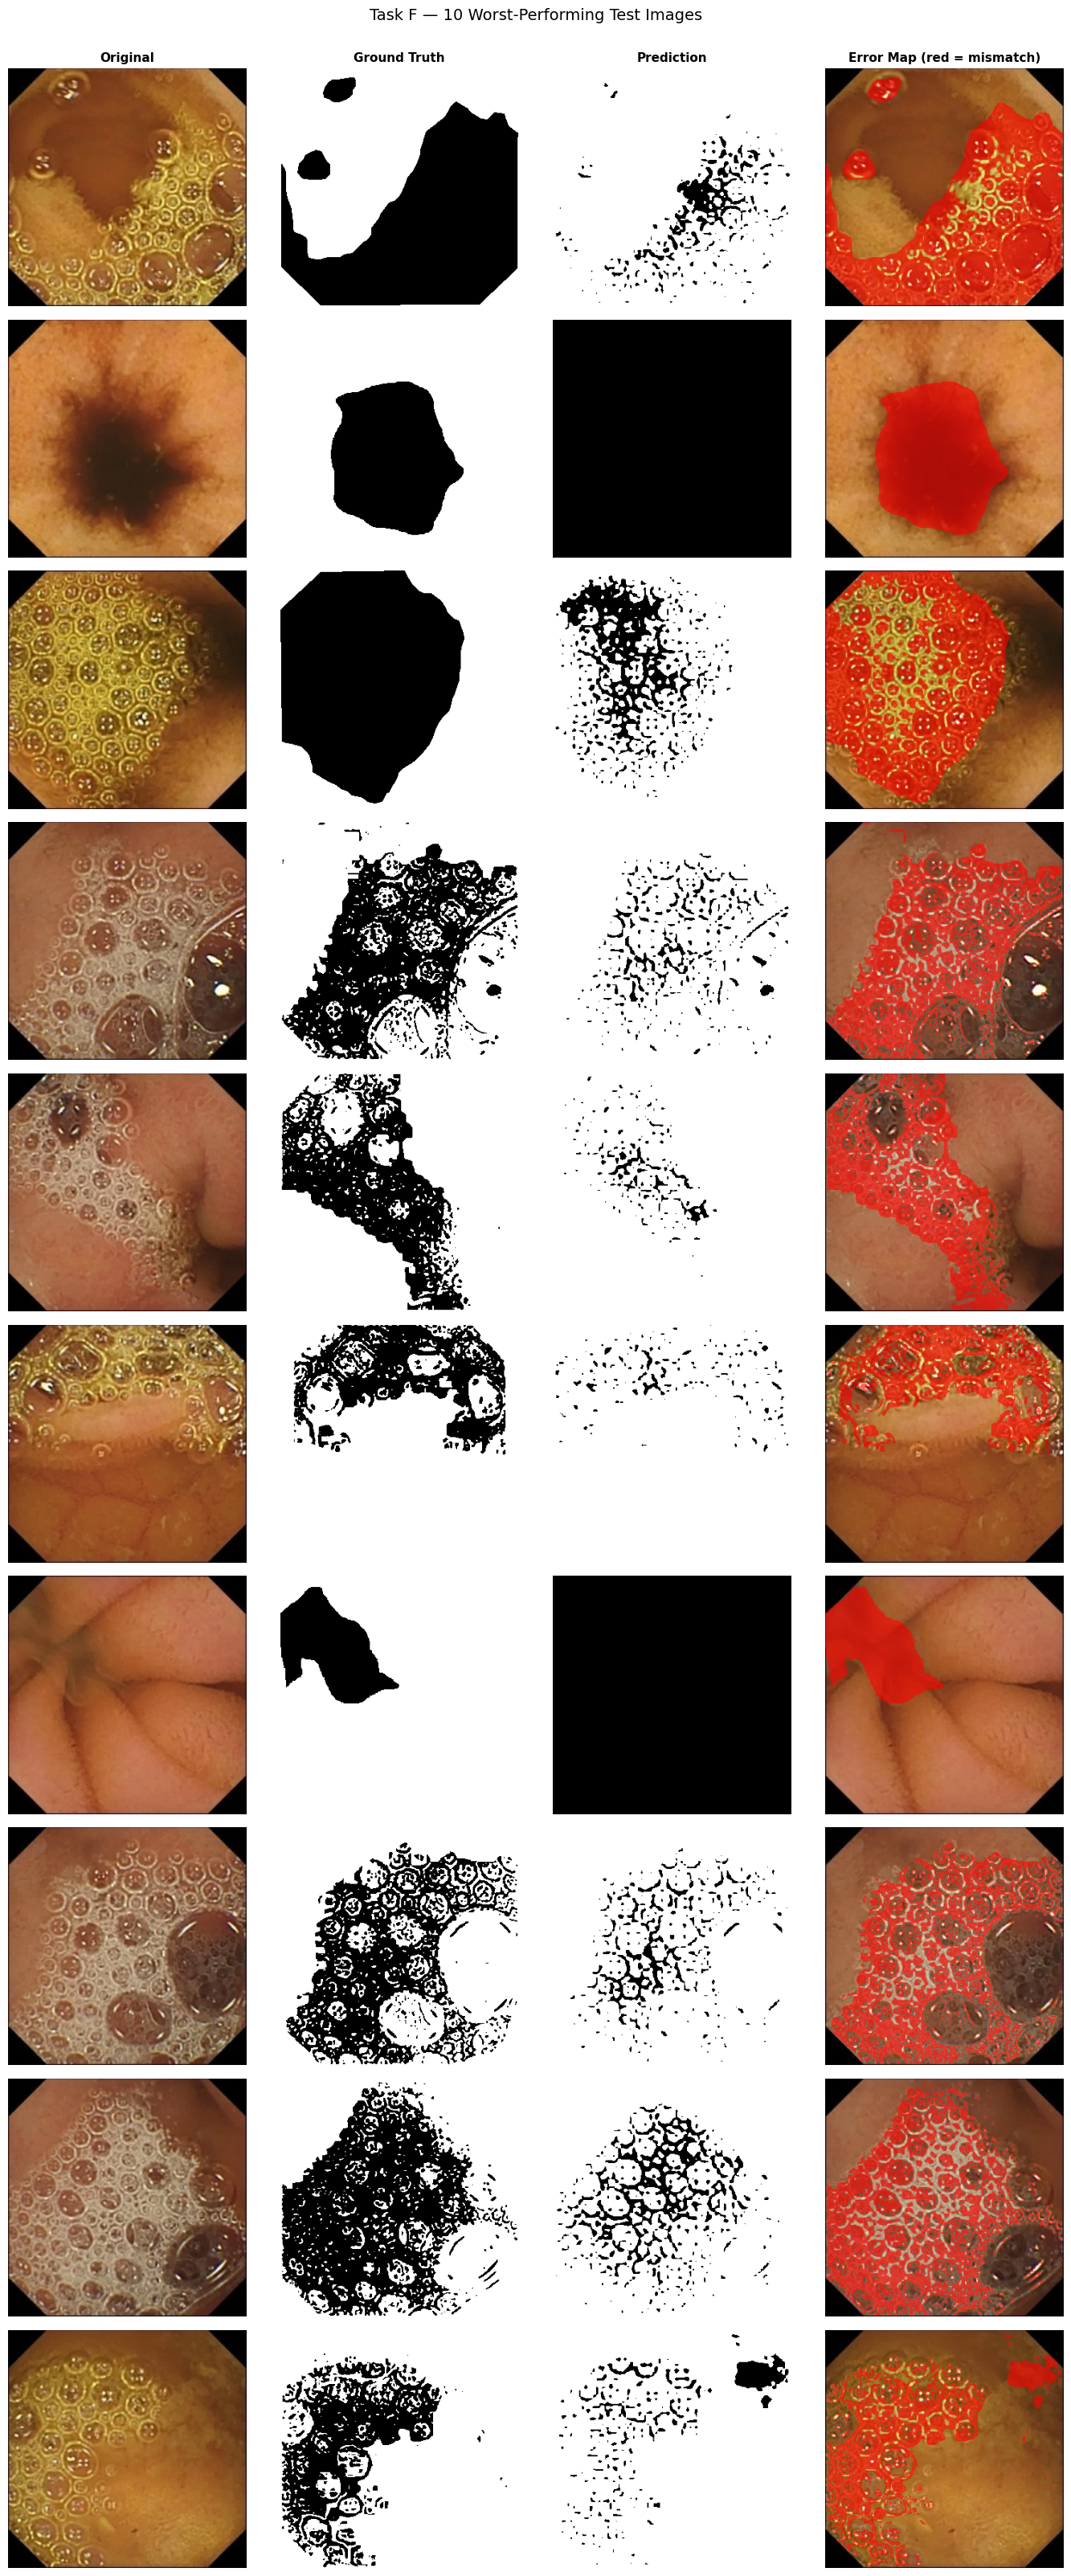

Saved -> results/simclr/error_analysis/worst_predictions.png


In [41]:
# ============================================================================
# STEP 2 -- WORST-PERFORMING SAMPLES
# ============================================================================
WORST_N = 10
worst_samples = per_image_df.head(WORST_N).reset_index(drop=True)

_norm = default_tensor_conversion_transform()

def _predict_single(image_rgb):
    tensor = _norm(image=image_rgb)["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = eval_model(tensor)
    return logits.argmax(dim=1).squeeze(0).cpu().numpy()


fig, axes = plt.subplots(WORST_N, 4, figsize=(14, 3.2 * WORST_N))
for row_idx, rec in worst_samples.iterrows():
    _row = test_df[test_df["image_filename"] == rec["image_id"]].iloc[0]
    _img = cv2.resize(read_image_rgb(_row["image_path"]), IMAGE_SIZE[::-1])
    _gt = cv2.resize(binary_mask_to_label(read_mask_grayscale(_row["binary_mask_path"]), label_mapping["white_pixel_label"]),
                      IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
    _pred = _predict_single(_img)
    _overlay = _img.copy()
    _overlay[_pred != _gt] = (0.6 * np.array([255, 0, 0]) + 0.4 * _overlay[_pred != _gt]).astype(np.uint8)

    for col_idx, (im, title, cmap) in enumerate(zip(
        [_img, _gt, _pred, _overlay],
        ["Original", "Ground Truth", "Prediction", "Error Map (red = mismatch)"],
        [None, "gray", "gray", None],
    )):
        ax = axes[row_idx, col_idx]
        ax.imshow(im, cmap=cmap)
        ax.axis("off")
        if row_idx == 0:
            ax.set_title(title, fontsize=11)
    axes[row_idx, 0].set_ylabel(f"IoU={rec['iou']:.3f}\nDice={rec['dice']:.3f}", fontsize=9, rotation=0,
                                 labelpad=55, va="center")

fig.suptitle(f"Task F — {WORST_N} Worst-Performing Test Images", y=1.001, fontsize=14)
fig.tight_layout()
fig.savefig(ERROR_DIR / "worst_predictions.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'worst_predictions.png'}")

### Step 3 — Failure Analysis (fill in yourselves)

The figure above and the quantitative hooks below are computed for you.
**The interpretation is not** — per the assignment's AI Usage Policy, this
reasoning must be your own, and it is exactly what the viva will test
(Section 9.1's coding questions ask you to walk through error cases directly).

Use `worst_samples`, `per_image_df`, and the `failure_patterns.png` plot below
to write your own analysis of, at minimum:

- **Boundary ambiguity** — do the worst cases show errors concentrated at
  contamination *edges* rather than spread across the whole region?
- **Contamination localisation / extremely small regions** — does the
  scatter plot below show a relationship between `contaminated_percent` and
  IoU? A very small contaminated area is much easier to entirely miss
  (large relative error) even with a small absolute pixel-count error.
- **Class imbalance effects** — does the model default to predicting the
  majority class (whichever `label_mapping` value dominates pixel counts) in
  its worst failures?
- **Illumination / texture similarity** — inspect the original-image column
  above: do the worst cases share visibly unusual lighting or texture that
  could be confused with contamination?
- **False positives vs. false negatives** — does the "Error Map" column above
  show mostly over-prediction (red spilling outside the true contaminated
  region) or under-prediction (red inside it, i.e. missed contamination)?

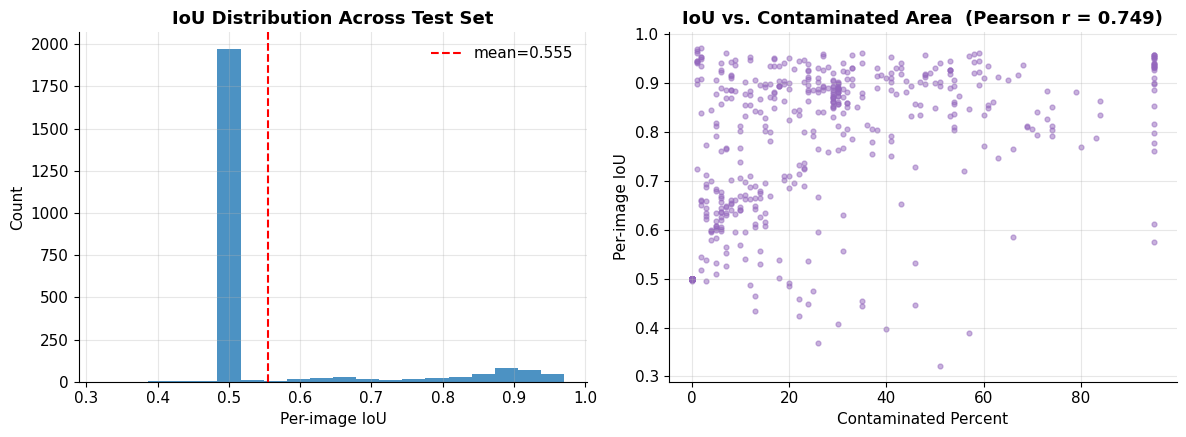

Saved -> results/simclr/error_analysis/failure_patterns.png

Correlation (contaminated_percent vs. IoU): r = 0.749
(A quantitative hook only -- state in your own words whether this supports the 'small regions are harder' hypothesis, and why, for your report.)


In [42]:
# ============================================================================
# QUANTITATIVE HOOKS FOR THE FAILURE-PATTERN DISCUSSION
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(per_image_df["iou"], bins=20, color="tab:blue", alpha=0.8)
axes[0].axvline(per_image_df["iou"].mean(), color="red", linestyle="--", label=f"mean={per_image_df['iou'].mean():.3f}")
axes[0].set_xlabel("Per-image IoU"); axes[0].set_ylabel("Count"); axes[0].set_title("IoU Distribution Across Test Set")
axes[0].legend()

_valid = per_image_df.dropna(subset=["contaminated_percent"])
if len(_valid) > 1:
    axes[1].scatter(_valid["contaminated_percent"], _valid["iou"], s=12, alpha=0.5, color="tab:purple")
    _corr = _valid["contaminated_percent"].corr(_valid["iou"])
    axes[1].set_title(f"IoU vs. Contaminated Area  (Pearson r = {_corr:.3f})")
else:
    _corr = None
    axes[1].text(0.5, 0.5, "contaminated_percent not available", ha="center", va="center")
axes[1].set_xlabel("Contaminated Percent"); axes[1].set_ylabel("Per-image IoU")

fig.tight_layout()
fig.savefig(ERROR_DIR / "failure_patterns.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'failure_patterns.png'}")
if _corr is not None:
    print(f"\nCorrelation (contaminated_percent vs. IoU): r = {_corr:.3f}")
    print("(A quantitative hook only -- state in your own words whether this supports the "
          "'small regions are harder' hypothesis, and why, for your report.)")

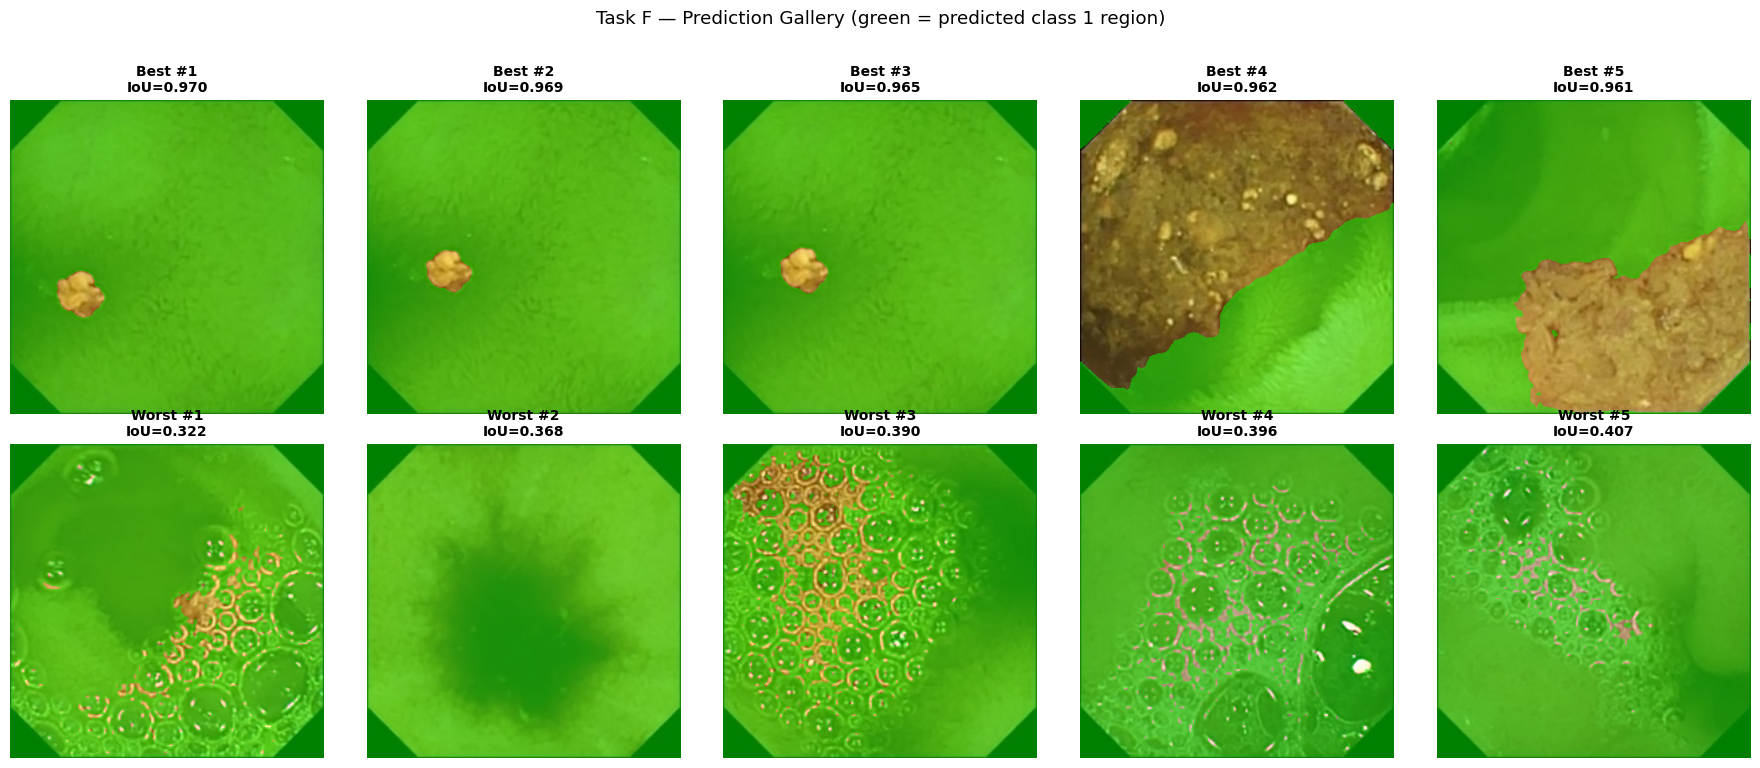

Saved -> results/simclr/error_analysis/prediction_gallery.png


In [43]:
# ============================================================================
# PREDICTION GALLERY -- best 5 vs. worst 5, side by side
# ============================================================================
best_samples = per_image_df.tail(5).iloc[::-1].reset_index(drop=True)
worst_5 = per_image_df.head(5).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for gallery_row, (samples, label) in enumerate([(best_samples, "Best"), (worst_5, "Worst")]):
    for col_idx, rec in samples.iterrows():
        _row = test_df[test_df["image_filename"] == rec["image_id"]].iloc[0]
        _img = cv2.resize(read_image_rgb(_row["image_path"]), IMAGE_SIZE[::-1])
        _gt = cv2.resize(binary_mask_to_label(read_mask_grayscale(_row["binary_mask_path"]), label_mapping["white_pixel_label"]),
                          IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
        _pred = _predict_single(_img)
        _overlay = _img.copy()
        _overlay[_pred == 1] = (0.5 * np.array([0, 255, 0]) + 0.5 * _overlay[_pred == 1]).astype(np.uint8)
        axes[gallery_row, col_idx].imshow(_overlay)
        axes[gallery_row, col_idx].axis("off")
        axes[gallery_row, col_idx].set_title(f"{label} #{col_idx+1}\nIoU={rec['iou']:.3f}", fontsize=10)

fig.suptitle("Task F — Prediction Gallery (green = predicted class 1 region)", y=1.02)
fig.tight_layout()
fig.savefig(ERROR_DIR / "prediction_gallery.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'prediction_gallery.png'}")

### Step 4 — Comparison with the Part-A Baseline

The cell below looks for Part A's own per-image metrics export and, if
found, joins on `image_filename` to show which specific images improved or
worsened under SimCLR. If Part A didn't export per-image results, only the
quantitative (overall mIoU) comparison from Task E is available — that's
stated explicitly rather than silently skipped.

In [44]:
# ============================================================================
# STEP 4 -- COMPARISON WITH PART-A BASELINE (per-image, if available)
# ============================================================================
_part_a_per_image_candidates = [
    PART_A_OUTPUT_DIR / "error_analysis" / "per_image_metrics.csv",
    PART_A_OUTPUT_DIR / "evaluation" / "per_image_metrics.csv",
]
_part_a_per_image_path = next((p for p in _part_a_per_image_candidates if p.is_file()), None)

if _part_a_per_image_path is not None:
    part_a_per_image_df = pd.read_csv(_part_a_per_image_path)
    _id_col = "image_filename" if "image_filename" in part_a_per_image_df.columns else "image_id"
    _merged = per_image_df.merge(
        part_a_per_image_df[[_id_col, "iou"]].rename(columns={_id_col: "image_id", "iou": "part_a_iou"}),
        on="image_id", how="inner",
    )
    _merged["iou_delta"] = _merged["iou"] - _merged["part_a_iou"]
    display(Markdown("### Per-Image IoU Delta vs. Part-A (SimCLR - Part-A)"))
    display(Markdown("**Most improved:**"))
    display(_merged.sort_values("iou_delta", ascending=False).head(5)[["image_id", "part_a_iou", "iou", "iou_delta"]].style.hide(axis="index"))
    display(Markdown("**Most worsened:**"))
    display(_merged.sort_values("iou_delta").head(5)[["image_id", "part_a_iou", "iou", "iou_delta"]].style.hide(axis="index"))
    _merged.to_csv(ERROR_DIR / "part_a_comparison.csv", index=False)
    print(f"Saved -> {ERROR_DIR / 'part_a_comparison.csv'}")
else:
    print(
        "Part A's per-image metrics were not found at any of the candidate paths below -- only the "
        "overall mIoU/Dice/Pixel-Accuracy comparison from Task E is available; a per-image, "
        "side-by-side failure comparison against Part A is not possible without that export.\n"
        + "\n".join(f"  {p}" for p in _part_a_per_image_candidates)
    )

Part A's per-image metrics were not found at any of the candidate paths below -- only the overall mIoU/Dice/Pixel-Accuracy comparison from Task E is available; a per-image, side-by-side failure comparison against Part A is not possible without that export.
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/error_analysis/per_image_metrics.csv
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/evaluation/per_image_metrics.csv


### Step 5 — Qualitative Summary (fill in yourselves)

In your own words, in this cell, cover:

- **Strengths of SimCLR representations** on this dataset's visual structure.
- **Remaining weaknesses** — what kind of image still trips the model up?
- **Effect of the small labelled fine-tuning set** — does the error pattern
  look like it would improve with more labels, or is it a representation
  limitation that more labels alone wouldn't fix?
- **Implications for wireless capsule endoscopy segmentation specifically**
  (e.g. deployment on limited-annotation clinical datasets).
- **Recommendations for future improvement** (e.g. stronger augmentations,
  longer pretraining, a different SSL method — tie this to what you'll
  actually see when BYOL/MAE/DINOv2 results come in).

In [45]:
# ============================================================================
# EXPORT -- Task F artifacts
# ============================================================================
per_image_df.to_csv(ERROR_DIR / "per_image_metrics.csv", index=False)

_error_report_lines = [
    "=" * 78, "ERROR ANALYSIS SUMMARY (Task F)", "=" * 78, "",
    f"Images evaluated          : {len(per_image_df)}",
    f"Mean IoU                  : {per_image_df['iou'].mean():.4f}",
    f"Std. dev. IoU             : {per_image_df['iou'].std():.4f}",
    f"Worst {WORST_N} image IDs         : {worst_samples['image_id'].tolist()}",
    f"Worst {WORST_N} IoU values        : {[round(v, 4) for v in worst_samples['iou'].tolist()]}",
    f"IoU vs. contaminated_percent corr: {_corr if _corr is not None else 'N/A'}",
    f"Avg. inference time/image  : {avg_inference_time_per_image * 1000:.2f} ms",
    "", "=" * 78,
]
(ERROR_DIR / "error_analysis_report.txt").write_text("\n".join(_error_report_lines))

_error_summary_json = {
    "n_images_evaluated": len(per_image_df), "mean_iou": float(per_image_df["iou"].mean()),
    "std_iou": float(per_image_df["iou"].std()), "worst_n": WORST_N,
    "worst_image_ids": worst_samples["image_id"].tolist(), "worst_iou_values": worst_samples["iou"].tolist(),
    "iou_vs_contaminated_percent_corr": _corr, "avg_inference_time_ms": avg_inference_time_per_image * 1000,
}
with open(ERROR_DIR / "error_analysis_summary.json", "w") as f:
    json.dump(_error_summary_json, f, indent=2, default=str)

print(f"Saved -> {ERROR_DIR / 'per_image_metrics.csv'}")
print(f"Saved -> {ERROR_DIR / 'error_analysis_report.txt'}")
print(f"Saved -> {ERROR_DIR / 'error_analysis_summary.json'}")

Saved -> results/simclr/error_analysis/per_image_metrics.csv
Saved -> results/simclr/error_analysis/error_analysis_report.txt
Saved -> results/simclr/error_analysis/error_analysis_summary.json


---
# Section 9 — Export Results

Consolidates everything the Final Comparison notebook needs into
`results/simclr/summary/simclr_results.json`, plus confirms every artifact
required by earlier sections is present on disk.

In [46]:
# ============================================================================
# CONSOLIDATED simclr_results.json
# ============================================================================
_pretrain_total_time_min = history_df["elapsed_time_sec"].iloc[-1] / 60 if len(history_df) else None
_finetune_total_time_min = fine_tuning_history_df["epoch_time_sec"].sum() / 60 if len(fine_tuning_history_df) else None
_training_time_min = (
    (_pretrain_total_time_min or 0) + (_finetune_total_time_min or 0)
    if _pretrain_total_time_min is not None and _finetune_total_time_min is not None else None
)

simclr_results = {
    "model_name": "simclr_resnet50_segformer_kvasir",
    "ssl_method": "SimCLR",
    "encoder": "ResNet-50",
    "decoder": "SegFormer All-MLP head",
    "pretrained_checkpoint": PRETRAIN_TRAIN_CONFIG["pretrained_checkpoint"],
    "strategy": _best_ckpt["strategy"],
    "n_labelled_images": _n_finetune_labelled,
    "n_unlabelled_images": len(train_df),
    "miou": final_metrics["miou"],
    "per_class_iou": dict(zip(CLASS_NAMES, final_metrics["per_class_iou"].tolist())),
    "dice": final_metrics["dice"],
    "pixel_accuracy": final_metrics["pixel_accuracy"],
    "mean_pixel_accuracy": final_metrics["mean_pixel_accuracy"],
    "training_time_min": _training_time_min,
    "pretraining_time_min": _pretrain_total_time_min,
    "finetuning_time_min": _finetune_total_time_min,
    "inference_time_ms_per_image": avg_inference_time_per_image * 1000,
    "best_epoch": _best_ckpt["epoch"],
    "checkpoint_path": str(CHECKPOINTS_DIR / "best_segmentation_model.pt"),
    "encoder_checkpoint_path": str(CHECKPOINTS_DIR / "encoder_checkpoint.pt"),
    "random_seed": RANDOM_SEED,
    "export_timestamp": datetime.now().isoformat(timespec="seconds"),
}

SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
with open(SUMMARY_DIR / "simclr_results.json", "w") as f:
    json.dump(simclr_results, f, indent=2, default=str)

display(Markdown("### `simclr_results.json` (consolidated for the Final Comparison notebook)"))
display(pd.DataFrame([{"Key": k, "Value": v} for k, v in simclr_results.items()]).style.hide(axis="index"))
print(f"Saved -> {SUMMARY_DIR / 'simclr_results.json'}")

### `simclr_results.json` (consolidated for the Final Comparison notebook)

Key,Value
model_name,simclr_resnet50_segformer_kvasir
ssl_method,SimCLR
encoder,ResNet-50
decoder,SegFormer All-MLP head
pretrained_checkpoint,torchvision ResNet50_Weights.IMAGENET1K_V2 (documented alternative -- see Section 4 markdown)
strategy,finetune
n_labelled_images,2206
n_unlabelled_images,10526
miou,0.893759
per_class_iou,"{'Contaminated': 0.8003274347313186, 'Clear': 0.9871914502940365}"


Saved -> results/simclr/summary/simclr_results.json


In [47]:
# ============================================================================
# FINAL ARTIFACT-PRESENCE CHECK
# ============================================================================
_expected_artifacts = [
    CHECKPOINTS_DIR / "encoder_checkpoint.pt", CHECKPOINTS_DIR / "best_segmentation_model.pt",
    EVAL_DIR / "evaluation_metrics.json", EVAL_DIR / "evaluation_summary.csv", EVAL_DIR / "label_efficiency_comparison.csv",
    LOGS_DIR / "training_history.csv", LOGS_DIR / "fine_tuning_history.csv",
    FIGURES_DIR / "pretraining_loss_curve.png", FIGURES_DIR / "fine_tuning_curves.png",
    FIGURES_DIR / "confusion_matrix.png", ERROR_DIR / "worst_predictions.png", ERROR_DIR / "prediction_gallery.png",
    REPORTS_DIR / "pretraining_summary.txt", REPORTS_DIR / "fine_tuning_summary.txt", ERROR_DIR / "error_analysis_report.txt",
    SUMMARY_DIR / "simclr_results.json",
]
_presence_rows = [{"Artifact": str(p.relative_to(OUTPUT_DIR.parent.parent) if OUTPUT_DIR.parent.parent in p.parents else p),
                    "Present": "OK" if p.is_file() else "MISSING"} for p in _expected_artifacts]
display(Markdown("### Final Artifact-Presence Check"))
display(pd.DataFrame(_presence_rows).style.hide(axis="index"))
_missing_final = [r["Artifact"] for r in _presence_rows if r["Present"] == "MISSING"]
if _missing_final:
    print(f"\nWARNING -- missing artifacts: {_missing_final}")
else:
    print("\nAll artifacts required by the Final Comparison notebook are present.")

### Final Artifact-Presence Check

Artifact,Present
results/simclr/checkpoints/encoder_checkpoint.pt,OK
results/simclr/checkpoints/best_segmentation_model.pt,OK
results/simclr/evaluation/evaluation_metrics.json,OK
results/simclr/evaluation/evaluation_summary.csv,OK
results/simclr/evaluation/label_efficiency_comparison.csv,OK
results/simclr/logs/training_history.csv,OK
results/simclr/logs/fine_tuning_history.csv,OK
results/simclr/figures/pretraining_loss_curve.png,OK
results/simclr/figures/fine_tuning_curves.png,OK
results/simclr/figures/confusion_matrix.png,OK



All artifacts required by the Final Comparison notebook are present.


---
# Section 10 — Notebook Summary

- SimCLR self-supervised pretraining completed successfully.
- Encoder checkpoint exported.
- SegFormer All-MLP decoder attached successfully.
- Downstream supervised fine-tuning completed.
- Test-set evaluation completed.
- Label-efficiency analysis completed.
- Comprehensive error analysis completed.
- All experimental artifacts exported successfully.
- The notebook is now ready for the Final Comparison notebook.

## Complete Experimental Pipeline

```
Data-Preparation Notebook
        │
        │ (validated preprocessing artifacts)
        ▼
This SimCLR Notebook
        │
        ├── Load preprocessing artifacts
        ├── Instantiate SSL datasets & dataloaders          (Task A)
        ├── SimCLR self-supervised pretraining               (Task B)
        ├── Attach SegFormer All-MLP decoder                 (Task C)
        ├── Supervised fine-tuning                           (Task D)
        ├── Test-set evaluation                              (Task E)
        ├── Label-efficiency analysis                        (Task E)
        ├── Error analysis                                   (Task F)
        └── Export standardized results (simclr_results.json)
```

No preprocessing, augmentation design, role mapping, metadata generation, or
sanity verification was repeated anywhere in this notebook — every one of
those was reused, unmodified, from the validated Data-Preparation notebook.
This is what guarantees reproducibility, prevents data leakage, and ensures
that these SimCLR results are directly comparable with the upcoming BYOL,
MAE, and DINOv2 notebooks under identical experimental conditions.